In [2]:

from google.colab import files

uploaded = files.upload()


Saving clustering.csv.gz to clustering.csv.gz


In [3]:

import pandas as pd
import numpy as np

df_cluster = pd.read_csv(
    "clustering.csv.gz",
    compression="gzip"
)

print("UKURAN DATASET:", df_cluster.shape)

display(df_cluster.head())


UKURAN DATASET: (120000, 60)


,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,...,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
0,C864291,8.8,6,540100.0,90000.0,3,0.0052,0.0332,0.0885,0.2438,...,0.071,-1.872,36.108,3.407,4.0,-0.413,3.468,0.943,0.377,23.328
1,C115620,14.6,6,6035900.0,1006000.0,3,0.1721,0.1303,0.1001,0.1456,...,0.006,0.230,41.069,6.218,5.0,-15.530,4.849,0.998,-2.110,67.995
2,C903774,4.1,15,4006600.0,267100.0,1,0.0636,0.0000,0.0164,0.2187,...,0.888,-0.848,80.620,3.552,6.0,2.881,4.269,0.002,-0.812,82.082
3,C716498,21.9,2,659500.0,329800.0,1,0.1899,0.1197,0.0040,0.0536,...,0.608,1.076,86.465,2.978,3.0,2.790,10.409,0.183,0.285,82.994
4,C936513,7.0,8,4056500.0,507100.0,4,0.0045,0.0503,0.0325,0.0326,...,0.829,-0.621,47.096,6.021,3.0,-24.985,7.796,0.812,1.262,60.364


In [4]:

# 1. Seluruh nama kolom
print("DAFTAR SELURUH KOLOM")
for i, kolom in enumerate(df_cluster.columns, start=1):
    print(f"{i}. {kolom}")

# 2. Informasi tipe data
print("\nTIPE DATA")
display(df_cluster.dtypes.value_counts())

display(df_cluster.dtypes.to_frame("tipe_data"))

# 3. Missing value
print("\nMISSING VALUE")
audit_missing = pd.DataFrame({
    "jumlah_missing": df_cluster.isnull().sum(),
    "persentase_missing": df_cluster.isnull().mean() * 100
}).sort_values("jumlah_missing", ascending=False)

display(audit_missing)

# 4. Duplikasi
print("\nDUPLIKASI")
print("Duplikat seluruh baris:", df_cluster.duplicated().sum())
print("Duplikat ID pelanggan:",
      df_cluster["id_pelanggan"].duplicated().sum())

# 5. Jumlah nilai unik
print("\nJUMLAH NILAI UNIK")
display(
    df_cluster.nunique()
    .sort_values()
    .to_frame("jumlah_nilai_unik")
)


DAFTAR SELURUH KOLOM
1. id_pelanggan
2. recency_hari
3. frekuensi_90h
4. belanja_90h
5. rata2_keranjang
6. item_per_pesanan
7. porsi_fashion
8. porsi_elektronik
9. porsi_kecantikan
10. porsi_rumah_tangga
11. porsi_makanan_minuman
12. porsi_ibu_bayi
13. porsi_olahraga
14. porsi_hobi
15. porsi_otomotif
16. porsi_kesehatan
17. porsi_buku_alat_tulis
18. porsi_voucher_digital
19. porsi_gadget_aksesoris
20. porsi_perabot
21. porsi_pertanian
22. porsi_lainnya
23. porsi_jam_pagi
24. porsi_jam_siang
25. porsi_jam_sore
26. porsi_jam_malam
27. persen_voucher
28. persen_flash_sale
29. persen_paylater
30. persen_cod
31. retur_90h
32. rating_beri_rata2
33. ulasan_90h
34. sesi_per_minggu
35. durasi_sesi_menit
36. rasio_konversi
37. lama_member_bulan
38. umur
39. kota_tier
40. perangkat
41. jumlah_alamat
42. wishlist
43. klik_iklan_30h
44. belanja_30h
45. frekuensi_30h
46. n01
47. n02
48. n03
49. n04
50. n05
51. n06
52. n07
53. n08
54. n09
55. n10
56. n11
57. n12
58. n13
59. n14
60. n15

TIPE DATA


,count
float64,48
int64,10
object,2


,tipe_data
id_pelanggan,object
recency_hari,float64
frekuensi_90h,int64
belanja_90h,float64
rata2_keranjang,float64
item_per_pesanan,int64
porsi_fashion,float64
porsi_elektronik,float64
porsi_kecantikan,float64
porsi_rumah_tangga,float64



MISSING VALUE


,jumlah_missing,persentase_missing
rata2_keranjang,6736,5.613333
id_pelanggan,0,0.000000
frekuensi_90h,0,0.000000
recency_hari,0,0.000000
belanja_90h,0,0.000000
item_per_pesanan,0,0.000000
porsi_fashion,0,0.000000
porsi_elektronik,0,0.000000
porsi_kecantikan,0,0.000000
porsi_rumah_tangga,0,0.000000



DUPLIKASI
Duplikat seluruh baris: 0
Duplikat ID pelanggan: 0

JUMLAH NILAI UNIK


,jumlah_nilai_unik
perangkat,3
kota_tier,3
jumlah_alamat,6
n03,16
n10,16
retur_90h,20
ulasan_90h,34
item_per_pesanan,45
umur,49
frekuensi_30h,61


In [5]:

# Kolom porsi waktu
kolom_porsi_waktu = [
    "porsi_jam_pagi",
    "porsi_jam_siang",
    "porsi_jam_sore",
    "porsi_jam_malam"
]

# Kolom porsi kategori
kolom_porsi_kategori = [
    c for c in df_cluster.columns
    if c.startswith("porsi_") and c not in kolom_porsi_waktu
]

print("JUMLAH FITUR PORSI KATEGORI:",
      len(kolom_porsi_kategori))

print("\nFITUR PORSI KATEGORI:")
print(kolom_porsi_kategori)

# Total porsi kategori per pelanggan
total_kategori = df_cluster[kolom_porsi_kategori].sum(axis=1)

print("\nSTATISTIK TOTAL PORSI KATEGORI")
display(total_kategori.describe())

# Total porsi waktu per pelanggan
total_waktu = df_cluster[kolom_porsi_waktu].sum(axis=1)

print("\nSTATISTIK TOTAL PORSI WAKTU")
display(total_waktu.describe())

# Pemeriksaan penyimpangan dari angka 1
print("\nPELANGGAN DENGAN TOTAL PORSI KATEGORI TIDAK MENDEKATI 1:")
print((~np.isclose(total_kategori, 1, atol=0.01)).sum())

print("\nPELANGGAN DENGAN TOTAL PORSI WAKTU TIDAK MENDEKATI 1:")
print((~np.isclose(total_waktu, 1, atol=0.01)).sum())


JUMLAH FITUR PORSI KATEGORI: 16

FITUR PORSI KATEGORI:
['porsi_fashion', 'porsi_elektronik', 'porsi_kecantikan', 'porsi_rumah_tangga', 'porsi_makanan_minuman', 'porsi_ibu_bayi', 'porsi_olahraga', 'porsi_hobi', 'porsi_otomotif', 'porsi_kesehatan', 'porsi_buku_alat_tulis', 'porsi_voucher_digital', 'porsi_gadget_aksesoris', 'porsi_perabot', 'porsi_pertanian', 'porsi_lainnya']

STATISTIK TOTAL PORSI KATEGORI


,0
count,120000.000000
mean,0.999995
std,0.000113
min,0.999600
25%,0.999900
50%,1.000000
75%,1.000100
max,1.000500



STATISTIK TOTAL PORSI WAKTU


,0
count,120000.000000
mean,1.000000
std,0.000058
min,0.999900
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000100



PELANGGAN DENGAN TOTAL PORSI KATEGORI TIDAK MENDEKATI 1:
0

PELANGGAN DENGAN TOTAL PORSI WAKTU TIDAK MENDEKATI 1:
0


In [6]:

# Memeriksa hubungan missing value dengan frekuensi transaksi

print("DISTRIBUSI FREKUENSI PELANGGAN DENGAN RATA-RATA KERANJANG KOSONG")

display(
    df_cluster.loc[
        df_cluster["rata2_keranjang"].isna(),
        "frekuensi_90h"
    ].value_counts().sort_index().to_frame("jumlah_pelanggan")
)

print("\nSTATISTIK FREKUENSI BERDASARKAN STATUS MISSING")

df_cluster["status_rata2_kosong"] = (
    df_cluster["rata2_keranjang"].isna()
)

display(
    df_cluster.groupby("status_rata2_kosong")[
        "frekuensi_90h"
    ].describe()
)

print("\nFREKUENSI TRANSAKSI NOL")

print(
    "Jumlah pelanggan frekuensi 0:",
    (df_cluster["frekuensi_90h"] == 0).sum()
)

print(
    "Jumlah pelanggan frekuensi 0 dengan rata-rata keranjang kosong:",
    (
        (df_cluster["frekuensi_90h"] == 0) &
        (df_cluster["rata2_keranjang"].isna())
    ).sum()
)


DISTRIBUSI FREKUENSI PELANGGAN DENGAN RATA-RATA KERANJANG KOSONG


,jumlah_pelanggan
frekuensi_90h,
0,6736



STATISTIK FREKUENSI BERDASARKAN STATUS MISSING


,count,mean,std,min,25%,50%,75%,max
status_rata2_kosong,,,,,,,,
False,113264.0,10.282605,10.975243,1.0,4.0,7.0,13.0,204.0
True,6736.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0



FREKUENSI TRANSAKSI NOL
Jumlah pelanggan frekuensi 0: 6736
Jumlah pelanggan frekuensi 0 dengan rata-rata keranjang kosong: 6736


In [7]:

# Mengambil fitur numerik selain ID
fitur_numerik = df_cluster.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Statistik distribusi
statistik_fitur = df_cluster[fitur_numerik].describe().T

# Menambahkan skewness
statistik_fitur["skewness"] = (
    df_cluster[fitur_numerik].skew()
)

print("STATISTIK DAN SKEWNESS FITUR NUMERIK")
display(statistik_fitur.round(3))

# Mengurutkan fitur berdasarkan skewness absolut
print("\n15 FITUR DENGAN SKEWNESS TERTINGGI")

display(
    statistik_fitur.assign(
        skewness_abs=statistik_fitur["skewness"].abs()
    )
    .sort_values("skewness_abs", ascending=False)
    .head(15)
    .round(3)
)


STATISTIK DAN SKEWNESS FITUR NUMERIK


,count,mean,std,min,25%,50%,75%,max,skewness
recency_hari,120000.0,24.543,49.010,0.200,5.400,10.100,21.800,2.039800e+03,7.943
frekuensi_90h,120000.0,9.705,10.922,0.000,3.000,7.000,13.000,2.040000e+02,3.527
belanja_90h,120000.0,2936216.427,5716273.207,0.000,410300.000,1136500.000,3060225.000,2.618368e+08,7.468
rata2_keranjang,113264.0,280384.330,300796.619,9800.000,108800.000,183900.000,330500.000,6.457500e+06,3.566
item_per_pesanan,120000.0,3.042,2.577,1.000,1.000,2.000,4.000,5.100000e+01,3.476
porsi_fashion,120000.0,0.141,0.136,0.000,0.040,0.100,0.200,9.700000e-01,1.595
porsi_elektronik,120000.0,0.064,0.082,0.000,0.009,0.035,0.087,9.130000e-01,2.547
porsi_kecantikan,120000.0,0.091,0.099,0.000,0.020,0.059,0.126,9.370000e-01,2.014
porsi_rumah_tangga,120000.0,0.091,0.098,0.000,0.021,0.060,0.129,9.040000e-01,1.983
porsi_makanan_minuman,120000.0,0.148,0.140,0.000,0.044,0.107,0.210,9.870000e-01,1.533



15 FITUR DENGAN SKEWNESS TERTINGGI


,count,mean,std,min,25%,50%,75%,max,skewness,skewness_abs
n12,120000.0,19.791,158.245,0.000,2.107,5.880,15.204,3.932884e+04,149.412,149.412
n05,120000.0,19.381,135.802,0.000,2.134,5.858,15.222,2.562943e+04,115.322,115.322
n02,120000.0,19.587,47.312,0.017,2.855,7.356,18.816,2.533811e+03,13.821,13.821
n09,120000.0,19.538,44.861,0.015,2.853,7.422,19.109,2.843352e+03,12.533,12.533
sesi_per_minggu,120000.0,10.072,31.204,0.190,3.330,5.510,8.600,3.999000e+02,9.194,9.194
belanja_30h,120000.0,1041766.564,2168737.727,0.000,132375.000,377950.000,1048425.000,1.011585e+08,8.190,8.190
recency_hari,120000.0,24.543,49.010,0.200,5.400,10.100,21.800,2.039800e+03,7.943,7.943
belanja_90h,120000.0,2936216.427,5716273.207,0.000,410300.000,1136500.000,3060225.000,2.618368e+08,7.468,7.468
klik_iklan_30h,120000.0,8.942,24.269,0.000,2.000,5.000,9.000,2.440000e+02,7.448,7.448
wishlist,120000.0,13.435,18.971,0.000,5.000,10.000,16.000,1.850000e+02,5.763,5.763


In [8]:

# Pemeriksaan nilai negatif dan nol
audit_nilai = pd.DataFrame({
    "jumlah_negatif": (df_cluster[fitur_numerik] < 0).sum(),
    "jumlah_nol": (df_cluster[fitur_numerik] == 0).sum(),
    "nilai_minimum": df_cluster[fitur_numerik].min(),
    "nilai_maksimum": df_cluster[fitur_numerik].max()
})

print("PEMERIKSAAN NILAI NEGATIF, NOL, DAN RENTANG")
display(audit_nilai)

# Menghitung batas outlier menggunakan IQR
Q1 = df_cluster[fitur_numerik].quantile(0.25)
Q3 = df_cluster[fitur_numerik].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

jumlah_outlier = (
    (df_cluster[fitur_numerik] < batas_bawah) |
    (df_cluster[fitur_numerik] > batas_atas)
).sum()

persentase_outlier = (
    jumlah_outlier / len(df_cluster) * 100
)

hasil_outlier = pd.DataFrame({
    "jumlah_outlier": jumlah_outlier,
    "persentase_outlier": persentase_outlier
}).sort_values("persentase_outlier", ascending=False)

print("\nFITUR DENGAN OUTLIER BERDASARKAN IQR")
display(hasil_outlier.round(3))


PEMERIKSAAN NILAI NEGATIF, NOL, DAN RENTANG


,jumlah_negatif,jumlah_nol,nilai_minimum,nilai_maksimum
recency_hari,0,0,0.200,2.039800e+03
frekuensi_90h,0,6736,0.000,2.040000e+02
belanja_90h,0,6736,0.000,2.618368e+08
rata2_keranjang,0,0,9800.000,6.457500e+06
item_per_pesanan,0,0,1.000,5.100000e+01
porsi_fashion,0,755,0.000,9.695000e-01
porsi_elektronik,0,4511,0.000,9.134000e-01
porsi_kecantikan,0,1963,0.000,9.366000e-01
porsi_rumah_tangga,0,1703,0.000,9.044000e-01
porsi_makanan_minuman,0,510,0.000,9.866000e-01



FITUR DENGAN OUTLIER BERDASARKAN IQR


,jumlah_outlier,persentase_outlier
n04,18733,15.611
n11,18576,15.480
recency_hari,14649,12.208
belanja_30h,12653,10.544
n05,12633,10.528
n12,12631,10.526
n02,12481,10.401
belanja_90h,12440,10.367
n09,12378,10.315
porsi_pertanian,11148,9.290


In [9]:

print("DISTRIBUSI PERANGKAT")

display(
    df_cluster["perangkat"]
    .value_counts(dropna=False)
    .to_frame("jumlah")
)

print("\nDISTRIBUSI KOTA TIER")

display(
    df_cluster["kota_tier"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("jumlah")
)


DISTRIBUSI PERANGKAT


,jumlah
perangkat,
android,77760
ios,31710
web,10530



DISTRIBUSI KOTA TIER


,jumlah
kota_tier,
1,47961
2,41741
3,30298


In [10]:

# Membuat salinan untuk audit
# Menghindari kolom tambahan status_rata2_kosong masuk ke analisis
df_audit = df_cluster.drop(
    columns=["status_rata2_kosong"],
    errors="ignore"
).copy()

kolom_anonim = [
    f"n{i:02d}" for i in range(1, 16)
]

# Menghitung korelasi Pearson
korelasi_anonim = df_audit[kolom_anonim].corr(
    method="pearson"
)

print("KORELASI ANTARFITUR ANONIM")
display(korelasi_anonim.round(3))

# Mengambil pasangan fitur dengan korelasi absolut tertinggi
pasangan_korelasi = (
    korelasi_anonim.where(
        np.triu(
            np.ones(korelasi_anonim.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

pasangan_korelasi.columns = [
    "fitur_1", "fitur_2", "korelasi"
]

pasangan_korelasi["korelasi_abs"] = (
    pasangan_korelasi["korelasi"].abs()
)

pasangan_korelasi = pasangan_korelasi.sort_values(
    "korelasi_abs",
    ascending=False
)

print("\n15 PASANGAN FITUR ANONIM DENGAN KORELASI TERTINGGI")
display(pasangan_korelasi.head(15).round(3))


KORELASI ANTARFITUR ANONIM


,n01,n02,n03,n04,n05,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
n01,1.000,0.002,0.003,0.003,0.001,-0.000,-0.002,-0.005,0.005,-0.001,-0.005,0.001,0.001,-0.001,0.001
n02,0.002,1.000,-0.001,-0.002,-0.003,-0.004,-0.002,-0.004,0.008,-0.005,-0.001,0.003,-0.003,0.004,-0.001
n03,0.003,-0.001,1.000,-0.005,-0.002,0.003,-0.001,-0.002,-0.005,-0.001,-0.001,0.002,0.000,-0.005,-0.000
n04,0.003,-0.002,-0.005,1.000,0.000,0.002,0.005,0.003,0.002,0.002,0.001,-0.001,-0.000,-0.004,-0.002
n05,0.001,-0.003,-0.002,0.000,1.000,0.001,-0.000,0.001,-0.000,-0.003,0.002,-0.001,-0.004,0.003,0.003
n06,-0.000,-0.004,0.003,0.002,0.001,1.000,-0.005,-0.002,-0.003,-0.002,0.005,0.003,0.000,0.004,0.004
n07,-0.002,-0.002,-0.001,0.005,-0.000,-0.005,1.000,0.004,-0.004,-0.001,0.001,-0.003,0.001,0.000,-0.002
n08,-0.005,-0.004,-0.002,0.003,0.001,-0.002,0.004,1.000,0.001,-0.005,-0.003,-0.005,0.002,0.002,0.004
n09,0.005,0.008,-0.005,0.002,-0.000,-0.003,-0.004,0.001,1.000,0.003,-0.004,-0.003,0.002,0.002,0.004
n10,-0.001,-0.005,-0.001,0.002,-0.003,-0.002,-0.001,-0.005,0.003,1.000,0.003,0.002,-0.001,-0.001,0.005



15 PASANGAN FITUR ANONIM DENGAN KORELASI TERTINGGI


,fitur_1,fitur_2,korelasi,korelasi_abs
20,n02,n09,0.008,0.008
98,n11,n15,-0.008,0.008
37,n03,n14,-0.005,0.005
6,n01,n08,-0.005,0.005
60,n06,n07,-0.005,0.005
21,n02,n10,-0.005,0.005
80,n08,n12,-0.005,0.005
94,n10,n15,0.005,0.005
9,n01,n11,-0.005,0.005
41,n04,n07,0.005,0.005


In [11]:

# Statistik persentil fitur anonim
persentil_anonim = df_audit[kolom_anonim].quantile([
    0, 0.01, 0.05, 0.25, 0.50,
    0.75, 0.95, 0.99, 1
]).T

print("DISTRIBUSI PERSENTIL FITUR ANONIM")
display(persentil_anonim.round(3))

# Memeriksa jumlah nilai negatif dan nilai pada batas ekstrem
print("\nJUMLAH NILAI NEGATIF DAN EKSTREM")

for kolom in kolom_anonim:
    jumlah_negatif = (df_audit[kolom] < 0).sum()
    jumlah_min = (df_audit[kolom] == df_audit[kolom].min()).sum()
    jumlah_max = (df_audit[kolom] == df_audit[kolom].max()).sum()

    print(
        f"{kolom}: negatif={jumlah_negatif}, "
        f"nilai_minimum={jumlah_min}, "
        f"nilai_maksimum={jumlah_max}"
    )


DISTRIBUSI PERSENTIL FITUR ANONIM


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
n01,0.001,0.980,5.006,25.003,50.114,74.986,95.059,99.001,99.999
n02,0.017,0.283,0.733,2.855,7.356,18.816,73.135,192.176,2533.811
n03,0.000,0.000,1.000,3.000,4.000,5.000,8.000,9.000,15.000
n04,-500.000,-32.201,-6.304,-0.999,-0.002,0.999,6.434,31.358,500.000
n05,0.000,0.067,0.353,2.134,5.858,15.222,62.846,204.122,25629.432
n06,0.000,0.000,0.006,0.147,0.501,0.854,0.994,1.000,1.000
n07,-4.509,-2.325,-1.649,-0.669,0.002,0.680,1.660,2.337,4.024
n08,0.002,0.974,5.056,24.917,49.832,74.874,94.927,98.982,99.999
n09,0.015,0.281,0.733,2.853,7.422,19.109,73.794,188.948,2843.352
n10,0.000,0.000,1.000,3.000,4.000,5.000,8.000,9.000,16.000



JUMLAH NILAI NEGATIF DAN EKSTREM
n01: negatif=0, nilai_minimum=2, nilai_maksimum=3
n02: negatif=0, nilai_minimum=1, nilai_maksimum=1
n03: negatif=0, nilai_minimum=2088, nilai_maksimum=1
n04: negatif=60082, nilai_minimum=83, nilai_maksimum=85
n05: negatif=0, nilai_minimum=6, nilai_maksimum=1
n06: negatif=0, nilai_minimum=1682, nilai_maksimum=1677
n07: negatif=59836, nilai_minimum=1, nilai_maksimum=1
n08: negatif=0, nilai_minimum=1, nilai_maksimum=1
n09: negatif=0, nilai_minimum=1, nilai_maksimum=1
n10: negatif=0, nilai_minimum=2154, nilai_maksimum=1
n11: negatif=59954, nilai_minimum=81, nilai_maksimum=74
n12: negatif=0, nilai_minimum=12, nilai_maksimum=1
n13: negatif=0, nilai_minimum=1640, nilai_maksimum=1694
n14: negatif=59655, nilai_minimum=1, nilai_maksimum=1
n15: negatif=0, nilai_minimum=1, nilai_maksimum=1


In [12]:

# Menghitung korelasi semua fitur numerik
korelasi_semua = df_audit[
    fitur_numerik
].corr(method="pearson").abs()

# Mengambil pasangan fitur dengan korelasi absolut tinggi
mask = np.triu(
    np.ones(korelasi_semua.shape),
    k=1
).astype(bool)

pasangan_semua = (
    korelasi_semua.where(mask)
    .stack()
    .reset_index()
)

pasangan_semua.columns = [
    "fitur_1", "fitur_2", "korelasi_abs"
]

pasangan_semua = pasangan_semua.sort_values(
    "korelasi_abs",
    ascending=False
)

print("30 PASANGAN FITUR DENGAN KORELASI TERTINGGI")
display(pasangan_semua.head(30).round(3))


30 PASANGAN FITUR DENGAN KORELASI TERTINGGI


,fitur_1,fitur_2,korelasi_abs
151,belanja_90h,belanja_30h,0.926
97,frekuensi_90h,frekuensi_30h,0.926
1335,sesi_per_minggu,klik_iklan_30h,0.889
1482,wishlist,klik_iklan_30h,0.862
1334,sesi_per_minggu,wishlist,0.811
86,frekuensi_90h,ulasan_90h,0.806
1312,ulasan_90h,frekuensi_30h,0.746
89,frekuensi_90h,rasio_konversi,0.692
57,frekuensi_90h,belanja_90h,0.669
1384,rasio_konversi,frekuensi_30h,0.640


In [13]:

# Membuat salinan dataset
df_cluster_model = df_cluster.copy()

# Menghapus kolom ID pelanggan
X_cluster = df_cluster_model.drop(
    columns=["id_pelanggan", "status_rata2_kosong"],
    errors="ignore"
).copy()

# Memastikan kolom target/label tidak ada
print("UKURAN DATA FITUR:", X_cluster.shape)

print("\nTIPE DATA FITUR")
display(X_cluster.dtypes.value_counts())

print("\nJUMLAH MISSING VALUE")
print(X_cluster.isnull().sum().sum())


UKURAN DATA FITUR: (120000, 59)

TIPE DATA FITUR


,count
float64,48
int64,10
object,1



JUMLAH MISSING VALUE
6736


In [14]:

# Mengisi rata-rata keranjang yang kosong dengan 0
X_cluster["rata2_keranjang"] = (
    X_cluster["rata2_keranjang"].fillna(0)
)

print("MISSING VALUE SETELAH PENANGANAN")
print(X_cluster.isnull().sum().sum())

print("\nPEMERIKSAAN PELANGGAN TANPA TRANSAKSI")
display(
    X_cluster.loc[
        X_cluster["frekuensi_90h"] == 0,
        ["frekuensi_90h", "belanja_90h", "rata2_keranjang"]
    ].head()
)


MISSING VALUE SETELAH PENANGANAN
0

PEMERIKSAAN PELANGGAN TANPA TRANSAKSI


,frekuensi_90h,belanja_90h,rata2_keranjang
15,0,0.0,0.0
20,0,0.0,0.0
35,0,0.0,0.0
36,0,0.0,0.0
63,0,0.0,0.0


In [15]:

# Fitur non-negatif yang memiliki distribusi sangat menceng
fitur_log = [
    "recency_hari",
    "frekuensi_90h",
    "belanja_90h",
    "rata2_keranjang",
    "item_per_pesanan",
    "retur_90h",
    "ulasan_90h",
    "sesi_per_minggu",
    "rasio_konversi",
    "lama_member_bulan",
    "wishlist",
    "klik_iklan_30h",
    "belanja_30h",
    "frekuensi_30h",
    "n02",
    "n05",
    "n09",
    "n12"
]

# Transformasi log1p
for kolom in fitur_log:
    X_cluster[kolom] = np.log1p(
        X_cluster[kolom]
    )

# Fitur anonim yang memiliki nilai positif dan negatif
fitur_signed_log = [
    "n04",
    "n07",
    "n11",
    "n14"
]

# Transformasi signed log
for kolom in fitur_signed_log:
    X_cluster[kolom] = (
        np.sign(X_cluster[kolom]) *
        np.log1p(np.abs(X_cluster[kolom]))
    )

print("TRANSFORMASI BERHASIL")

print("\nSTATISTIK FITUR SETELAH TRANSFORMASI")
display(
    X_cluster[fitur_log + fitur_signed_log]
    .describe()
    .round(3)
)


TRANSFORMASI BERHASIL

STATISTIK FITUR SETELAH TRANSFORMASI


,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,retur_90h,ulasan_90h,sesi_per_minggu,rasio_konversi,lama_member_bulan,...,belanja_30h,frekuensi_30h,n02,n05,n09,n12,n04,n07,n11,n14
count,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,...,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000
mean,2.580,1.975,13.280,11.492,1.264,0.466,0.661,1.902,0.127,2.803,...,12.244,1.124,2.234,2.038,2.239,2.038,0.000,0.002,-0.004,0.004
std,1.016,0.918,3.489,2.916,0.484,0.537,0.656,0.728,0.128,0.752,...,3.274,0.783,1.156,1.193,1.157,1.197,1.265,0.623,1.257,0.622
min,0.182,0.000,0.000,0.000,0.693,0.000,0.000,0.174,0.000,0.262,...,0.000,0.000,0.017,0.000,0.015,0.000,-6.217,-1.706,-6.217,-1.623
25%,1.856,1.386,12.925,11.486,0.693,0.000,0.000,1.466,0.040,2.351,...,11.793,0.693,1.349,1.142,1.349,1.134,-0.693,-0.512,-0.695,-0.512
50%,2.407,2.079,13.943,12.061,1.099,0.000,0.693,1.873,0.090,2.833,...,12.843,1.099,2.123,1.925,2.131,1.929,-0.002,0.002,0.001,0.007
75%,3.127,2.639,14.934,12.666,1.609,0.693,1.099,2.262,0.171,3.300,...,13.863,1.609,2.986,2.786,3.001,2.785,0.693,0.519,0.685,0.519
max,7.621,5.323,19.383,15.681,3.951,3.258,3.584,5.994,1.663,5.934,...,18.432,4.394,7.838,10.152,7.953,10.580,6.217,1.614,6.217,1.708


In [16]:

from sklearn.preprocessing import RobustScaler

# One-hot encoding untuk perangkat
X_cluster = pd.get_dummies(
    X_cluster,
    columns=["perangkat"],
    dtype=int
)

# Memastikan seluruh fitur sudah numerik
print("TIPE DATA SETELAH ENCODING")
display(X_cluster.dtypes.value_counts())

# Scaling menggunakan RobustScaler
scaler = RobustScaler()

X_cluster_scaled = pd.DataFrame(
    scaler.fit_transform(X_cluster),
    columns=X_cluster.columns,
    index=X_cluster.index
)

print("\nUKURAN DATA SETELAH PREPROCESSING")
print(X_cluster_scaled.shape)

print("\nSTATISTIK DATA HASIL SCALING")
display(X_cluster_scaled.describe().round(3))

print("\nMISSING VALUE:", X_cluster_scaled.isnull().sum().sum())
print("INFINITE VALUE:", np.isinf(X_cluster_scaled).sum().sum())


TIPE DATA SETELAH ENCODING


,count
float64,55
int64,6



UKURAN DATA SETELAH PREPROCESSING
(120000, 61)

STATISTIK DATA HASIL SCALING


,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,porsi_makanan_minuman,...,n09,n10,n11,n12,n13,n14,n15,perangkat_android,perangkat_ios,perangkat_web
count,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,...,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000,120000.000
mean,0.136,-0.084,-0.330,-0.482,0.180,0.258,0.367,0.302,0.289,0.250,...,0.066,0.004,-0.004,0.066,0.001,-0.003,0.004,-0.352,0.264,0.088
std,0.799,0.733,1.736,2.470,0.528,0.853,1.046,0.936,0.911,0.841,...,0.700,1.002,0.911,0.725,0.501,0.603,0.578,0.478,0.441,0.283
min,-1.751,-1.660,-6.939,-10.214,-0.443,-0.625,-0.453,-0.552,-0.556,-0.642,...,-1.281,-2.000,-4.506,-1.168,-0.708,-1.582,-0.996,-1.000,0.000,0.000
25%,-0.433,-0.553,-0.507,-0.487,-0.443,-0.374,-0.336,-0.363,-0.363,-0.376,...,-0.473,-0.500,-0.505,-0.481,-0.498,-0.503,-0.495,-1.000,0.000,0.000
50%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000
75%,0.567,0.447,0.493,0.513,0.557,0.626,0.664,0.637,0.637,0.624,...,0.527,0.500,0.495,0.519,0.502,0.497,0.505,0.000,1.000,0.000
max,4.104,2.589,2.707,3.066,3.113,5.442,11.258,8.267,7.826,5.290,...,3.524,6.000,4.505,5.238,0.711,1.651,1.007,0.000,1.000,1.000



MISSING VALUE: 0
INFINITE VALUE: 0


In [17]:

from sklearn.model_selection import train_test_split

# Mengambil sampel 15.000 pelanggan
X_cluster_sample = X_cluster_scaled.sample(
    n=15000,
    random_state=42
)

print("Ukuran sampel:", X_cluster_sample.shape)
print("Jumlah fitur:", X_cluster_sample.shape[1])


Ukuran sampel: (15000, 61)
Jumlah fitur: 61


In [18]:

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

hasil_evaluasi_k = []

daftar_k = range(2, 9)

for k in daftar_k:

    print(f"Sedang menguji K = {k}")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    label = model.fit_predict(X_cluster_sample)

    hasil_evaluasi_k.append({
        "jumlah_cluster": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(
            X_cluster_sample,
            label
        ),
        "davies_bouldin": davies_bouldin_score(
            X_cluster_sample,
            label
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_cluster_sample,
            label
        )
    })

df_evaluasi_k = pd.DataFrame(hasil_evaluasi_k)

print("\nHASIL EVALUASI JUMLAH CLUSTER")
display(df_evaluasi_k.round(4))


Sedang menguji K = 2
Sedang menguji K = 3
Sedang menguji K = 4
Sedang menguji K = 5
Sedang menguji K = 6
Sedang menguji K = 7
Sedang menguji K = 8

HASIL EVALUASI JUMLAH CLUSTER


,jumlah_cluster,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,600488.4287,0.4688,0.8614,3873.6389
1,3,572061.6146,0.0750,3.1061,2405.5439
2,4,557295.6326,0.0749,3.0213,1778.5204
3,5,543840.4400,0.0676,3.2882,1459.5491
4,6,533584.1746,0.0680,3.3450,1247.6448
5,7,524997.3103,0.0697,3.2390,1097.5104
6,8,517265.9035,0.0706,3.1685,986.7315


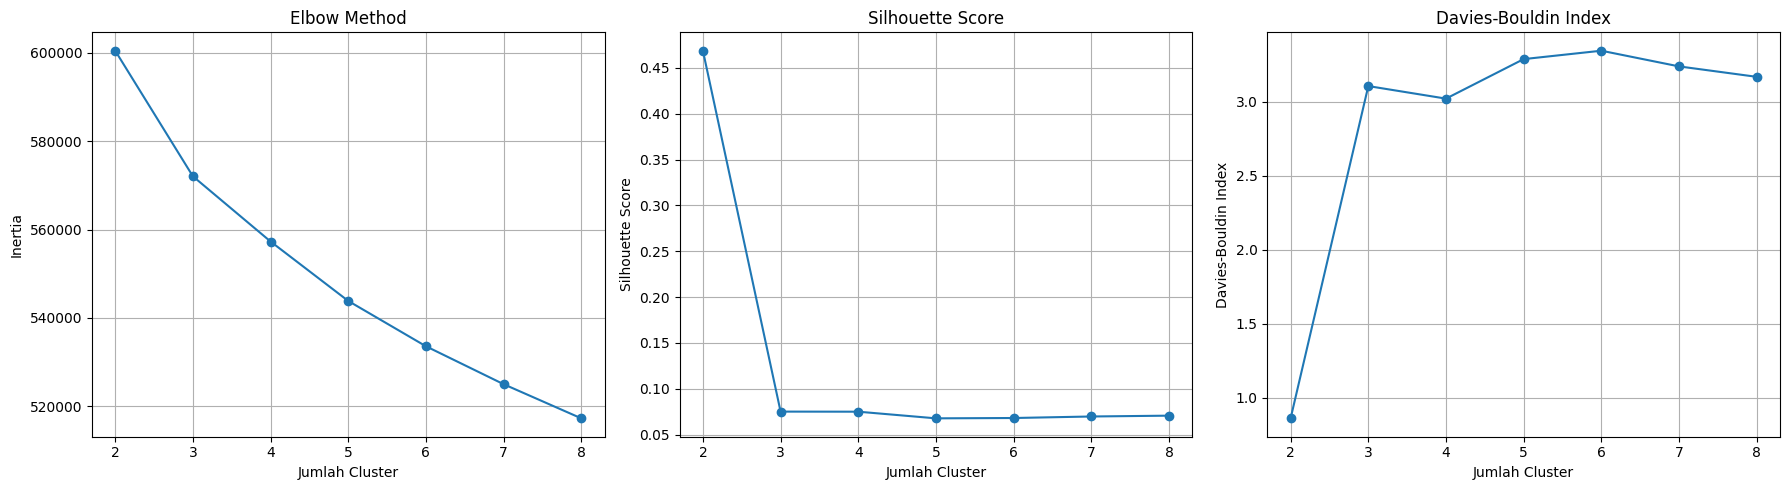

In [19]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafik Elbow
axes[0].plot(
    df_evaluasi_k["jumlah_cluster"],
    df_evaluasi_k["inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah Cluster")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

# Grafik Silhouette
axes[1].plot(
    df_evaluasi_k["jumlah_cluster"],
    df_evaluasi_k["silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Jumlah Cluster")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True)

# Grafik Davies-Bouldin
axes[2].plot(
    df_evaluasi_k["jumlah_cluster"],
    df_evaluasi_k["davies_bouldin"],
    marker="o"
)
axes[2].set_title("Davies-Bouldin Index")
axes[2].set_xlabel("Jumlah Cluster")
axes[2].set_ylabel("Davies-Bouldin Index")
axes[2].grid(True)

plt.tight_layout()
plt.show()


In [20]:

# Melatih K-Means dengan 2 cluster pada seluruh data
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

label_kmeans_2 = kmeans_2.fit_predict(X_cluster_scaled)

# Menyimpan label cluster
df_cluster_hasil = df_cluster.copy()
df_cluster_hasil["cluster"] = label_kmeans_2

print("DISTRIBUSI JUMLAH PELANGGAN PER CLUSTER")

distribusi_cluster = (
    df_cluster_hasil["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("jumlah_pelanggan")
)

distribusi_cluster["persentase"] = (
    distribusi_cluster["jumlah_pelanggan"] /
    len(df_cluster_hasil) * 100
)

display(distribusi_cluster.round(2))


DISTRIBUSI JUMLAH PELANGGAN PER CLUSTER


,jumlah_pelanggan,persentase
cluster,,
0,6736,5.61
1,113264,94.39


In [21]:

# Fitur utama untuk melihat karakteristik pelanggan
fitur_profil = [
    "recency_hari",
    "frekuensi_90h",
    "belanja_90h",
    "rata2_keranjang",
    "item_per_pesanan",
    "retur_90h",
    "rating_beri_rata2",
    "ulasan_90h",
    "sesi_per_minggu",
    "rasio_konversi",
    "lama_member_bulan",
    "umur",
    "wishlist",
    "klik_iklan_30h",
    "belanja_30h",
    "frekuensi_30h"
]

profil_cluster = (
    df_cluster_hasil
    .groupby("cluster")[fitur_profil]
    .median()
    .T
)

print("PROFIL MEDIAN SETIAP CLUSTER")
display(profil_cluster.round(2))


PROFIL MEDIAN SETIAP CLUSTER


cluster,0,1
recency_hari,38.45,9.60
frekuensi_90h,0.00,7.00
belanja_90h,0.00,1261000.00
rata2_keranjang,NaN,183900.00
item_per_pesanan,2.00,2.00
retur_90h,0.00,0.00
rating_beri_rata2,4.40,4.40
ulasan_90h,0.00,1.00
sesi_per_minggu,2.55,5.66
rasio_konversi,0.00,0.10


In [22]:

print("DISTRIBUSI PERANGKAT PADA SETIAP CLUSTER")

distribusi_perangkat = pd.crosstab(
    df_cluster_hasil["cluster"],
    df_cluster_hasil["perangkat"],
    normalize="index"
) * 100

display(distribusi_perangkat.round(2))


DISTRIBUSI PERANGKAT PADA SETIAP CLUSTER


perangkat,android,ios,web
cluster,,,
0,67.73,23.49,8.79
1,64.63,26.60,8.77


In [23]:

# Memeriksa karakteristik cluster 0
validasi_cluster_0 = df_cluster_hasil[
    df_cluster_hasil["cluster"] == 0
]

print("JUMLAH ANGGOTA CLUSTER 0:")
print(len(validasi_cluster_0))

print("\nDISTRIBUSI FREKUENSI TRANSAKSI 90 HARI:")
print(
    validasi_cluster_0["frekuensi_90h"]
    .value_counts(dropna=False)
)

print("\nDISTRIBUSI BELANJA 90 HARI:")
print(
    validasi_cluster_0["belanja_90h"]
    .value_counts(dropna=False)
)

print("\nJUMLAH PELANGGAN DENGAN TRANSAKSI:")
print(
    (validasi_cluster_0["frekuensi_90h"] > 0).sum()
)


JUMLAH ANGGOTA CLUSTER 0:
6736

DISTRIBUSI FREKUENSI TRANSAKSI 90 HARI:
frekuensi_90h
0    6736
Name: count, dtype: int64

DISTRIBUSI BELANJA 90 HARI:
belanja_90h
0.0    6736
Name: count, dtype: int64

JUMLAH PELANGGAN DENGAN TRANSAKSI:
0


In [24]:

# Mengambil pelanggan yang memiliki transaksi
indeks_aktif = df_cluster[
    df_cluster["frekuensi_90h"] > 0
].index

# Mengambil fitur hasil scaling untuk pelanggan aktif
X_cluster_aktif = X_cluster_scaled.loc[indeks_aktif].copy()

print("JUMLAH PELANGGAN AKTIF:", len(X_cluster_aktif))
print("UKURAN DATA:", X_cluster_aktif.shape)

# Mengambil sampel pelanggan aktif
X_cluster_aktif_sample = X_cluster_aktif.sample(
    n=15000,
    random_state=42
)

print("UKURAN SAMPEL:", X_cluster_aktif_sample.shape)


JUMLAH PELANGGAN AKTIF: 113264
UKURAN DATA: (113264, 61)
UKURAN SAMPEL: (15000, 61)


In [25]:

hasil_evaluasi_aktif = []

for k in range(2, 9):

    print(f"Sedang menguji K = {k}")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    label = model.fit_predict(X_cluster_aktif_sample)

    hasil_evaluasi_aktif.append({
        "jumlah_cluster": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(
            X_cluster_aktif_sample,
            label
        ),
        "davies_bouldin": davies_bouldin_score(
            X_cluster_aktif_sample,
            label
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_cluster_aktif_sample,
            label
        )
    })

df_evaluasi_aktif = pd.DataFrame(
    hasil_evaluasi_aktif
)

print("\nHASIL EVALUASI K-MEANS PELANGGAN AKTIF")
display(df_evaluasi_aktif.round(4))


Sedang menguji K = 2
Sedang menguji K = 3
Sedang menguji K = 4
Sedang menguji K = 5
Sedang menguji K = 6
Sedang menguji K = 7
Sedang menguji K = 8

HASIL EVALUASI K-MEANS PELANGGAN AKTIF


,jumlah_cluster,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,569360.6015,0.0527,4.1737,804.6528
1,3,553823.7203,0.0533,3.7070,623.9472
2,4,539895.6452,0.0454,3.8836,555.6218
3,5,529143.3901,0.0460,3.8502,501.3304
4,6,520419.2179,0.0469,3.6788,458.0319
5,7,513287.5100,0.0421,3.6354,421.6901
6,8,505758.6158,0.0469,3.4449,398.6867


In [26]:

from sklearn.cluster import Birch

hasil_birch = []

for k in [2, 3, 4, 5, 6, 7, 8]:

    print(f"Sedang menguji BIRCH K = {k}")

    model_birch = Birch(
        threshold=0.5,
        branching_factor=50,
        n_clusters=k
    )

    label_birch = model_birch.fit_predict(
        X_cluster_aktif_sample
    )

    hasil_birch.append({
        "jumlah_cluster": k,
        "silhouette": silhouette_score(
            X_cluster_aktif_sample,
            label_birch
        ),
        "davies_bouldin": davies_bouldin_score(
            X_cluster_aktif_sample,
            label_birch
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_cluster_aktif_sample,
            label_birch
        )
    })

df_hasil_birch = pd.DataFrame(hasil_birch)

print("\nHASIL EVALUASI BIRCH")
display(df_hasil_birch.round(4))


Sedang menguji BIRCH K = 2
Sedang menguji BIRCH K = 3
Sedang menguji BIRCH K = 4
Sedang menguji BIRCH K = 5
Sedang menguji BIRCH K = 6
Sedang menguji BIRCH K = 7
Sedang menguji BIRCH K = 8

HASIL EVALUASI BIRCH


,jumlah_cluster,silhouette,davies_bouldin,calinski_harabasz
0,2,0.0205,5.9178,361.0325
1,3,0.0152,4.7059,349.1111
2,4,0.0122,5.2021,323.5255
3,5,0.0121,4.4950,306.5463
4,6,0.0164,4.2418,295.7557
5,7,0.0202,4.0450,286.6260
6,8,0.0240,4.0295,278.2289


In [27]:

from sklearn.mixture import GaussianMixture

hasil_gmm = []

for k in [2, 3, 4, 5, 6, 7, 8]:

    print(f"Sedang menguji GMM K = {k}")

    model_gmm = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        random_state=42,
        n_init=2,
        reg_covar=1e-5
    )

    label_gmm = model_gmm.fit_predict(
        X_cluster_aktif_sample
    )

    hasil_gmm.append({
        "jumlah_cluster": k,
        "silhouette": silhouette_score(
            X_cluster_aktif_sample,
            label_gmm
        ),
        "davies_bouldin": davies_bouldin_score(
            X_cluster_aktif_sample,
            label_gmm
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_cluster_aktif_sample,
            label_gmm
        ),
        "bic": model_gmm.bic(
            X_cluster_aktif_sample
        )
    })

df_hasil_gmm = pd.DataFrame(hasil_gmm)

print("\nHASIL EVALUASI GAUSSIAN MIXTURE MODEL")
display(df_hasil_gmm.round(4))


Sedang menguji GMM K = 2
Sedang menguji GMM K = 3
Sedang menguji GMM K = 4
Sedang menguji GMM K = 5
Sedang menguji GMM K = 6
Sedang menguji GMM K = 7
Sedang menguji GMM K = 8

HASIL EVALUASI GAUSSIAN MIXTURE MODEL


,jumlah_cluster,silhouette,davies_bouldin,calinski_harabasz,bic
0,2,0.0521,4.2031,777.8117,2.006497e+06
1,3,0.0309,4.5918,580.6592,1.970497e+06
2,4,0.0081,4.7231,357.8336,1.907073e+06
3,5,0.0061,5.1108,296.5395,1.894824e+06
4,6,0.0192,6.2772,249.5208,1.549834e+06
5,7,0.0095,5.2791,192.2341,1.566232e+06
6,8,0.0082,6.2109,229.3808,1.518893e+06


In [28]:

# Menambahkan nama algoritma
df_kmeans_compare = df_evaluasi_aktif.copy()
df_kmeans_compare["algoritma"] = "K-Means"

df_birch_compare = df_hasil_birch.copy()
df_birch_compare["algoritma"] = "BIRCH"

df_gmm_compare = df_hasil_gmm.copy()
df_gmm_compare["algoritma"] = "GMM"

# Menggabungkan hasil
df_perbandingan = pd.concat(
    [
        df_kmeans_compare,
        df_birch_compare,
        df_gmm_compare
    ],
    ignore_index=True
)

kolom_perbandingan = [
    "algoritma",
    "jumlah_cluster",
    "silhouette",
    "davies_bouldin",
    "calinski_harabasz"
]

print("PERBANDINGAN ALGORITMA CLUSTERING")

display(
    df_perbandingan[kolom_perbandingan]
    .sort_values(
        by="silhouette",
        ascending=False
    )
    .round(4)
)


PERBANDINGAN ALGORITMA CLUSTERING


,algoritma,jumlah_cluster,silhouette,davies_bouldin,calinski_harabasz
1,K-Means,3,0.0533,3.7070,623.9472
0,K-Means,2,0.0527,4.1737,804.6528
14,GMM,2,0.0521,4.2031,777.8117
6,K-Means,8,0.0469,3.4449,398.6867
4,K-Means,6,0.0469,3.6788,458.0319
3,K-Means,5,0.0460,3.8502,501.3304
2,K-Means,4,0.0454,3.8836,555.6218
5,K-Means,7,0.0421,3.6354,421.6901
15,GMM,3,0.0309,4.5918,580.6592
13,BIRCH,8,0.0240,4.0295,278.2289


In [29]:

# Membentuk model K-Means dengan 3 cluster
kmeans_aktif = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Melakukan clustering pada seluruh pelanggan aktif
label_aktif = kmeans_aktif.fit_predict(
    X_cluster_aktif
)

# Menyimpan hasil clustering
df_cluster_final = df_cluster.copy()

# Berikan label awal -1 untuk pelanggan tanpa transaksi
df_cluster_final["cluster"] = -1

# Masukkan label cluster untuk pelanggan aktif
df_cluster_final.loc[
    indeks_aktif,
    "cluster"
] = label_aktif

print("DISTRIBUSI CLUSTER SELURUH PELANGGAN")

display(
    df_cluster_final["cluster"]
    .value_counts()
    .sort_index()
    .rename("jumlah_pelanggan")
    .to_frame()
)

print("\nPERSENTASE ANGGOTA CLUSTER")

display(
    (
        df_cluster_final["cluster"]
        .value_counts(normalize=True)
        .sort_index() * 100
    )
    .round(2)
    .rename("persentase")
    .to_frame()
)


DISTRIBUSI CLUSTER SELURUH PELANGGAN


,jumlah_pelanggan
cluster,
-1,6736
0,9168
1,62240
2,41856



PERSENTASE ANGGOTA CLUSTER


,persentase
cluster,
-1,5.61
0,7.64
1,51.87
2,34.88


In [30]:

# Fitur utama untuk melihat karakteristik pelanggan
fitur_profil = [
    "recency_hari",
    "frekuensi_90h",
    "belanja_90h",
    "rata2_keranjang",
    "item_per_pesanan",
    "persen_voucher",
    "persen_flash_sale",
    "persen_paylater",
    "persen_cod",
    "retur_90h",
    "rating_beri_rata2",
    "ulasan_90h",
    "sesi_per_minggu",
    "durasi_sesi_menit",
    "rasio_konversi",
    "lama_member_bulan",
    "umur",
    "wishlist",
    "klik_iklan_30h",
    "belanja_30h",
    "frekuensi_30h"
]

# Profil median setiap cluster
profil_cluster = (
    df_cluster_final[
        df_cluster_final["cluster"] != -1
    ]
    .groupby("cluster")[fitur_profil]
    .median()
)

print("PROFIL MEDIAN PELANGGAN AKTIF")

display(profil_cluster.round(3))


PROFIL MEDIAN PELANGGAN AKTIF


,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,persen_voucher,persen_flash_sale,persen_paylater,persen_cod,retur_90h,...,ulasan_90h,sesi_per_minggu,durasi_sesi_menit,rasio_konversi,lama_member_bulan,umur,wishlist,klik_iklan_30h,belanja_30h,frekuensi_30h
cluster,,,,,,,,,,,,,,,,,,,,,
0,9.8,7.0,1366500.0,199350.0,2.0,0.452,0.336,0.148,0.244,0.0,...,1.0,5.81,7.91,0.104,16.2,33.0,9.0,5.0,458700.0,2.0
1,12.5,5.0,615500.0,135800.0,2.0,0.673,0.532,0.216,0.319,1.0,...,0.0,5.71,7.94,0.068,13.6,29.0,10.0,5.0,203400.0,1.0
2,6.8,13.0,3877350.0,307400.0,3.0,0.306,0.208,0.111,0.167,0.0,...,2.0,5.57,7.95,0.180,18.8,38.0,9.0,5.0,1316300.0,4.0


In [31]:

# Mengambil fitur proporsi kategori produk
fitur_kategori = [
    kolom for kolom in df_cluster.columns
    if kolom.startswith("porsi_")
    and kolom not in [
        "porsi_pagi",
        "porsi_siang",
        "porsi_sore",
        "porsi_malam"
    ]
]

# Menghitung median proporsi kategori setiap cluster
profil_kategori = (
    df_cluster_final[
        df_cluster_final["cluster"] != -1
    ]
    .groupby("cluster")[fitur_kategori]
    .median()
)

print("MEDIAN PROPORSI KATEGORI PRODUK")

display(
    (profil_kategori * 100).round(2)
)

# Menampilkan 5 kategori tertinggi pada setiap cluster
print("\n5 KATEGORI TERATAS SETIAP CLUSTER")

for cluster_id in profil_kategori.index:

    print(f"\nCLUSTER {cluster_id}")

    kategori_teratas = (
        profil_kategori.loc[cluster_id]
        .sort_values(ascending=False)
        .head(5) * 100
    )

    display(kategori_teratas.round(2).to_frame(
        "persentase_median"
    ))


MEDIAN PROPORSI KATEGORI PRODUK


,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,porsi_makanan_minuman,porsi_ibu_bayi,porsi_olahraga,porsi_hobi,porsi_otomotif,porsi_kesehatan,porsi_buku_alat_tulis,porsi_voucher_digital,porsi_gadget_aksesoris,porsi_perabot,porsi_pertanian,porsi_lainnya,porsi_jam_pagi,porsi_jam_siang,porsi_jam_sore,porsi_jam_malam
cluster,,,,,,,,,,,,,,,,,,,,
0,8.39,3.45,5.19,5.95,9.98,2.93,1.71,1.79,1.13,1.80,1.15,3.74,3.68,1.93,9.35,3.06,22.33,21.47,19.40,22.70
1,13.52,3.01,7.67,5.16,8.53,2.46,1.73,1.76,1.09,1.75,1.11,5.09,3.60,1.74,0.35,3.10,18.43,18.14,19.22,32.03
2,6.62,4.48,3.95,7.44,15.33,4.75,1.47,1.45,0.89,1.48,0.89,2.71,3.88,2.12,0.39,2.76,28.97,23.10,18.47,16.44



5 KATEGORI TERATAS SETIAP CLUSTER

CLUSTER 0


,persentase_median
porsi_jam_malam,22.70
porsi_jam_pagi,22.33
porsi_jam_siang,21.47
porsi_jam_sore,19.40
porsi_makanan_minuman,9.98



CLUSTER 1


,persentase_median
porsi_jam_malam,32.03
porsi_jam_sore,19.22
porsi_jam_pagi,18.43
porsi_jam_siang,18.14
porsi_fashion,13.52



CLUSTER 2


,persentase_median
porsi_jam_pagi,28.97
porsi_jam_siang,23.10
porsi_jam_sore,18.47
porsi_jam_malam,16.44
porsi_makanan_minuman,15.33


In [34]:

# Fitur waktu transaksi sesuai nama kolom dataset
fitur_waktu = [
    "porsi_jam_pagi",
    "porsi_jam_siang",
    "porsi_jam_sore",
    "porsi_jam_malam"
]

# Menghitung median proporsi waktu setiap cluster
profil_waktu = (
    df_cluster_final[
        df_cluster_final["cluster"] != -1
    ]
    .groupby("cluster")[fitur_waktu]
    .median()
)

print("PREFERENSI WAKTU TRANSAKSI")

display(
    (profil_waktu * 100).round(2)
)


PREFERENSI WAKTU TRANSAKSI


,porsi_jam_pagi,porsi_jam_siang,porsi_jam_sore,porsi_jam_malam
cluster,,,,
0,22.33,21.47,19.40,22.70
1,18.43,18.14,19.22,32.03
2,28.97,23.10,18.47,16.44


In [35]:

# Distribusi perangkat setiap cluster
print("DISTRIBUSI PERANGKAT SETIAP CLUSTER")

profil_perangkat = pd.crosstab(
    df_cluster_final["cluster"],
    df_cluster_final["perangkat"],
    normalize="index"
) * 100

display(profil_perangkat.round(2))


# Distribusi kota tier setiap cluster
print("\nDISTRIBUSI KOTA TIER SETIAP CLUSTER")

profil_kota = pd.crosstab(
    df_cluster_final["cluster"],
    df_cluster_final["kota_tier"],
    normalize="index"
) * 100

display(profil_kota.round(2))


DISTRIBUSI PERANGKAT SETIAP CLUSTER


perangkat,android,ios,web
cluster,,,
-1,67.73,23.49,8.79
0,65.13,26.20,8.67
1,70.86,19.39,9.75
2,55.24,37.41,7.35



DISTRIBUSI KOTA TIER SETIAP CLUSTER


kota_tier,1,2,3
cluster,,,
-1,40.45,34.55,25.00
0,39.93,35.26,24.80
1,40.00,34.65,25.35
2,39.84,34.92,25.24


In [36]:

fitur_anonim = [
    f"n{i:02d}" for i in range(1, 16)
]

profil_anonim = (
    df_cluster_final[
        df_cluster_final["cluster"] != -1
    ]
    .groupby("cluster")[fitur_anonim]
    .median()
)

print("PROFIL FITUR ANONIM SETIAP CLUSTER")

display(profil_anonim.round(3))


PROFIL FITUR ANONIM SETIAP CLUSTER


,n01,n02,n03,n04,n05,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
cluster,,,,,,,,,,,,,,,
0,50.060,7.390,4.0,-0.015,5.700,0.512,0.028,49.899,7.664,4.0,0.028,5.866,0.504,-0.010,49.876
1,50.174,7.357,4.0,-0.013,5.828,0.499,-0.003,49.862,7.317,4.0,0.002,5.906,0.501,0.015,49.519
2,50.225,7.326,4.0,0.013,5.918,0.504,0.004,49.780,7.494,4.0,-0.003,5.840,0.495,0.000,49.891


In [37]:

# Mengambil 16 fitur proporsi kategori produk saja
fitur_kategori = [
    kolom for kolom in df_cluster.columns
    if kolom.startswith("porsi_")
    and not kolom.startswith("porsi_jam_")
]

profil_kategori = (
    df_cluster_final[
        df_cluster_final["cluster"] != -1
    ]
    .groupby("cluster")[fitur_kategori]
    .median()
)

print("5 KATEGORI PRODUK TERATAS SETIAP CLUSTER")

for cluster_id in profil_kategori.index:

    print(f"\nCLUSTER {cluster_id}")

    kategori_teratas = (
        profil_kategori.loc[cluster_id]
        .sort_values(ascending=False)
        .head(5) * 100
    )

    display(
        kategori_teratas.round(2).to_frame(
            "persentase_median"
        )
    )


5 KATEGORI PRODUK TERATAS SETIAP CLUSTER

CLUSTER 0


,persentase_median
porsi_makanan_minuman,9.98
porsi_pertanian,9.35
porsi_fashion,8.39
porsi_rumah_tangga,5.95
porsi_kecantikan,5.19



CLUSTER 1


,persentase_median
porsi_fashion,13.52
porsi_makanan_minuman,8.53
porsi_kecantikan,7.67
porsi_rumah_tangga,5.16
porsi_voucher_digital,5.09



CLUSTER 2


,persentase_median
porsi_makanan_minuman,15.33
porsi_rumah_tangga,7.44
porsi_fashion,6.62
porsi_ibu_bayi,4.75
porsi_elektronik,4.48


In [38]:

from sklearn.metrics import adjusted_rand_score

hasil_stabilitas = []
hasil_label = []

# Menggunakan sampel pelanggan aktif yang sama
X_stabilitas = X_cluster_aktif_sample

# Menguji beberapa random state
for seed in [10, 21, 42, 55, 77]:

    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=10
    )

    label = model.fit_predict(X_stabilitas)

    hasil_label.append(label)

    hasil_stabilitas.append({
        "random_state": seed,
        "inertia": model.inertia_
    })

# Membandingkan hasil antarpercobaan
hasil_ari = []

for i in range(len(hasil_label)):
    for j in range(i + 1, len(hasil_label)):

        ari = adjusted_rand_score(
            hasil_label[i],
            hasil_label[j]
        )

        hasil_ari.append(ari)

print("HASIL PENGUJIAN MODEL")

display(
    pd.DataFrame(hasil_stabilitas).round(4)
)

print("\nNILAI ARI ANTARPERCOBAAN")

print(
    pd.Series(hasil_ari)
    .describe()
    .round(4)
)


HASIL PENGUJIAN MODEL


,random_state,inertia
0,10,553823.8893
1,21,553823.6122
2,42,553823.7203
3,55,553823.7078
4,77,553823.7656



NILAI ARI ANTARPERCOBAAN
count    10.0000
mean      0.9986
std       0.0007
min       0.9974
25%       0.9981
50%       0.9985
75%       0.9993
max       0.9995
dtype: float64


In [39]:

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Mengambil sampel evaluasi yang sama
indeks_evaluasi = X_cluster_aktif.sample(
    n=15000,
    random_state=42
).index

X_evaluasi = X_cluster_aktif.loc[indeks_evaluasi]

label_evaluasi = df_cluster_final.loc[
    indeks_evaluasi,
    "cluster"
].values

print("EVALUASI MODEL K-MEANS FINAL")

print(
    "Silhouette:",
    round(
        silhouette_score(X_evaluasi, label_evaluasi),
        4
    )
)

print(
    "Davies-Bouldin:",
    round(
        davies_bouldin_score(X_evaluasi, label_evaluasi),
        4
    )
)

print(
    "Calinski-Harabasz:",
    round(
        calinski_harabasz_score(X_evaluasi, label_evaluasi),
        4
    )
)


EVALUASI MODEL K-MEANS FINAL
Silhouette: 0.0534
Davies-Bouldin: 3.6924
Calinski-Harabasz: 623.5855


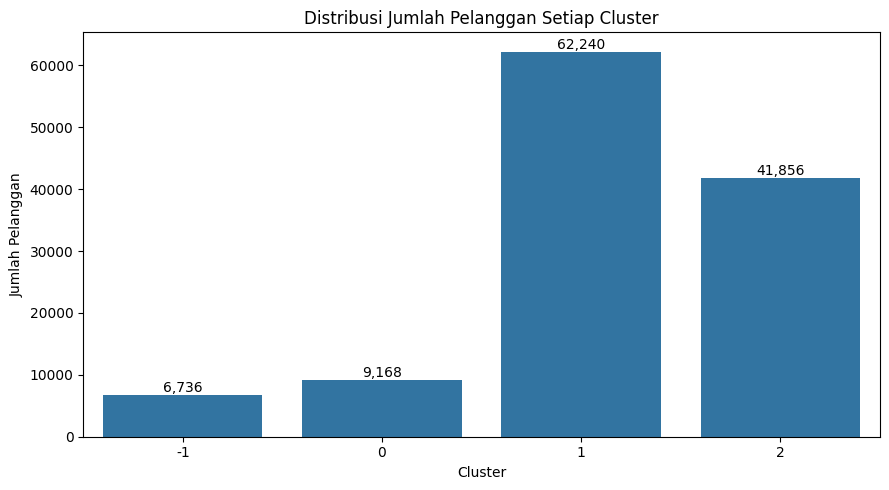

In [40]:

import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung jumlah anggota setiap cluster
distribusi = (
    df_cluster_final["cluster"]
    .value_counts()
    .sort_index()
)

# Grafik distribusi cluster
plt.figure(figsize=(9, 5))

sns.barplot(
    x=distribusi.index.astype(str),
    y=distribusi.values
)

plt.title("Distribusi Jumlah Pelanggan Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Jumlah Pelanggan")

for i, nilai in enumerate(distribusi.values):
    plt.text(
        i,
        nilai,
        f"{nilai:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


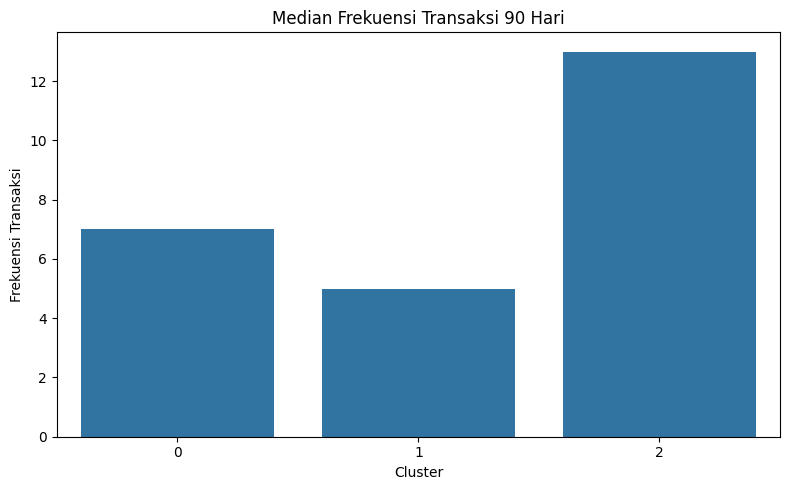

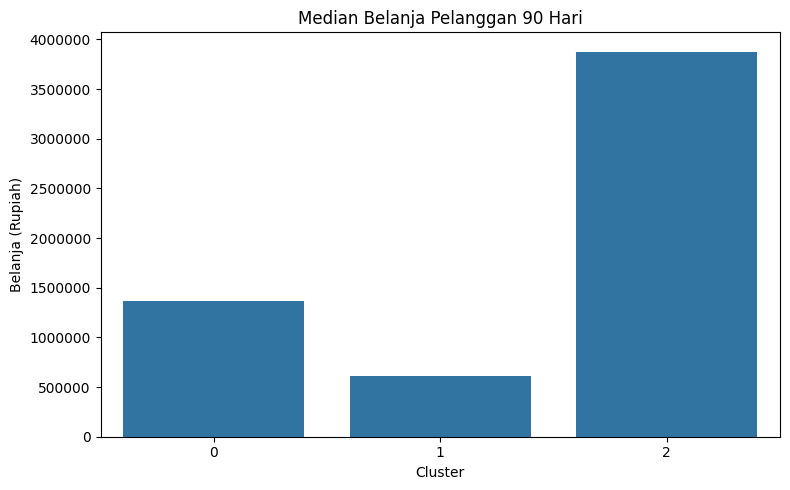

In [41]:

# Menghitung median fitur transaksi
fitur_visual = [
    "frekuensi_90h",
    "belanja_90h",
    "rata2_keranjang"
]

data_visual = (
    df_cluster_final[
        df_cluster_final["cluster"] != -1
    ]
    .groupby("cluster")[fitur_visual]
    .median()
)

# Visualisasi median frekuensi transaksi
plt.figure(figsize=(8, 5))

sns.barplot(
    x=data_visual.index.astype(str),
    y=data_visual["frekuensi_90h"]
)

plt.title("Median Frekuensi Transaksi 90 Hari")
plt.xlabel("Cluster")
plt.ylabel("Frekuensi Transaksi")

plt.tight_layout()
plt.show()


# Visualisasi median belanja
plt.figure(figsize=(8, 5))

sns.barplot(
    x=data_visual.index.astype(str),
    y=data_visual["belanja_90h"]
)

plt.title("Median Belanja Pelanggan 90 Hari")
plt.xlabel("Cluster")
plt.ylabel("Belanja (Rupiah)")

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()


In [42]:

# Mengidentifikasi fitur proporsi kategori dan waktu
fitur_kategori = [
    kolom for kolom in df_cluster.columns
    if kolom.startswith("porsi_")
    and not kolom.startswith("porsi_jam_")
]

fitur_waktu = [
    "porsi_jam_pagi",
    "porsi_jam_siang",
    "porsi_jam_sore",
    "porsi_jam_malam"
]

# Memeriksa jumlah fitur
print("JUMLAH FITUR KATEGORI:", len(fitur_kategori))
print("FITUR KATEGORI:", fitur_kategori)

print("\nJUMLAH FITUR WAKTU:", len(fitur_waktu))
print("FITUR WAKTU:", fitur_waktu)

# Memeriksa nilai nol dan minimum
print("\nAUDIT FITUR KOMPOSISIONAL")

for nama, kolom in [
    ("KATEGORI PRODUK", fitur_kategori),
    ("WAKTU TRANSAKSI", fitur_waktu)
]:

    data = df_cluster[kolom]

    print(f"\n{nama}")

    audit = pd.DataFrame({
        "jumlah_nol": (data == 0).sum(),
        "nilai_minimum": data.min(),
        "nilai_maksimum": data.max(),
        "jumlah_missing": data.isna().sum()
    })

    display(audit)

    print(
        "Jumlah baris dengan setidaknya satu nilai nol:",
        (data == 0).any(axis=1).sum()
    )


JUMLAH FITUR KATEGORI: 16
FITUR KATEGORI: ['porsi_fashion', 'porsi_elektronik', 'porsi_kecantikan', 'porsi_rumah_tangga', 'porsi_makanan_minuman', 'porsi_ibu_bayi', 'porsi_olahraga', 'porsi_hobi', 'porsi_otomotif', 'porsi_kesehatan', 'porsi_buku_alat_tulis', 'porsi_voucher_digital', 'porsi_gadget_aksesoris', 'porsi_perabot', 'porsi_pertanian', 'porsi_lainnya']

JUMLAH FITUR WAKTU: 4
FITUR WAKTU: ['porsi_jam_pagi', 'porsi_jam_siang', 'porsi_jam_sore', 'porsi_jam_malam']

AUDIT FITUR KOMPOSISIONAL

KATEGORI PRODUK


,jumlah_nol,nilai_minimum,nilai_maksimum,jumlah_missing
porsi_fashion,755,0.0,0.9695,0
porsi_elektronik,4511,0.0,0.9134,0
porsi_kecantikan,1963,0.0,0.9366,0
porsi_rumah_tangga,1703,0.0,0.9044,0
porsi_makanan_minuman,510,0.0,0.9866,0
porsi_ibu_bayi,5358,0.0,0.8589,0
porsi_olahraga,9765,0.0,0.7160,0
porsi_hobi,9529,0.0,0.8006,0
porsi_otomotif,14292,0.0,0.6358,0
porsi_kesehatan,9737,0.0,0.6436,0


Jumlah baris dengan setidaknya satu nilai nol: 73187

WAKTU TRANSAKSI


,jumlah_nol,nilai_minimum,nilai_maksimum,jumlah_missing
porsi_jam_pagi,33,0.0,0.9902,0
porsi_jam_siang,33,0.0,0.9695,0
porsi_jam_sore,37,0.0,0.9534,0
porsi_jam_malam,44,0.0,0.9983,0


Jumlah baris dengan setidaknya satu nilai nol: 146


In [43]:

# Memeriksa jumlah nilai nol pada setiap baris
nol_kategori = (df_cluster[fitur_kategori] == 0).sum(axis=1)
nol_waktu = (df_cluster[fitur_waktu] == 0).sum(axis=1)

print("DISTRIBUSI JUMLAH NILAI NOL KATEGORI")
display(nol_kategori.value_counts().sort_index())

print("\nDISTRIBUSI JUMLAH NILAI NOL WAKTU")
display(nol_waktu.value_counts().sort_index())

# Memeriksa jumlah nol berdasarkan aktivitas pelanggan
df_audit_nol = pd.DataFrame({
    "frekuensi_90h": df_cluster["frekuensi_90h"],
    "nol_kategori": nol_kategori,
    "nol_waktu": nol_waktu
})

df_audit_nol["status_aktivitas"] = np.where(
    df_audit_nol["frekuensi_90h"] == 0,
    "Tidak Aktif",
    "Aktif"
)

print("\nRATA-RATA JUMLAH NILAI NOL BERDASARKAN AKTIVITAS")
display(
    df_audit_nol.groupby("status_aktivitas")[
        ["nol_kategori", "nol_waktu"]
    ].agg(["mean", "median", "max"])
)

# Memeriksa jumlah proporsi per baris
print("\nPEMERIKSAAN JUMLAH PROPORSI")

print(
    "Kategori:",
    df_cluster[fitur_kategori].sum(axis=1).describe()
)

print(
    "\nWaktu:",
    df_cluster[fitur_waktu].sum(axis=1).describe()
)


DISTRIBUSI JUMLAH NILAI NOL KATEGORI


,count
0,46813
1,43206
2,20286
3,6965
4,2035
5,512
6,128
7,37
8,11
9,5



DISTRIBUSI JUMLAH NILAI NOL WAKTU


,count
0,119854
1,145
2,1



RATA-RATA JUMLAH NILAI NOL BERDASARKAN AKTIVITAS


nol_kategori            nol_waktu           
                         mean median max      mean median max
status_aktivitas                                             
Aktif                0.983905    1.0  10  0.001254    0.0   2
Tidak Aktif          0.758907    1.0   6  0.000742    0.0   1


PEMERIKSAAN JUMLAH PROPORSI
Kategori: count    120000.000000
mean          0.999995
std           0.000113
min           0.999600
25%           0.999900
50%           1.000000
75%           1.000100
max           1.000500
dtype: float64

Waktu: count    120000.000000
mean          1.000000
std           0.000058
min           0.999900
25%           1.000000
50%           1.000000
75%           1.000000
max           1.000100
dtype: float64


In [44]:

import numpy as np
import pandas as pd

# Fungsi multiplicative zero replacement
def multiplicative_replacement(data):
    X = data.to_numpy(dtype=float).copy()

    # Normalisasi agar setiap baris berjumlah 1
    X = X / X.sum(axis=1, keepdims=True)

    # Menentukan nilai pengganti dari nilai positif terkecil
    nilai_positif = X[X > 0]
    delta = nilai_positif.min() / 2

    # Mengganti nol dan menyesuaikan proporsi positif
    for i in range(X.shape[0]):
        mask_nol = X[i] == 0
        jumlah_nol = mask_nol.sum()

        if jumlah_nol > 0:
            jumlah_positif = X[i, ~mask_nol].sum()

            X[i, mask_nol] = delta
            X[i, ~mask_nol] *= (
                (1 - jumlah_nol * delta) / jumlah_positif
            )

    return pd.DataFrame(
        X,
        index=data.index,
        columns=data.columns
    ), delta


# Fungsi Centered Log-Ratio
def clr_transform(data):
    log_data = np.log(data)
    return log_data.sub(log_data.mean(axis=1), axis=0)


# Transformasi proporsi kategori
kategori_replaced, delta_kategori = multiplicative_replacement(
    df_cluster[fitur_kategori]
)

clr_kategori = clr_transform(kategori_replaced)


# Transformasi proporsi waktu
waktu_replaced, delta_waktu = multiplicative_replacement(
    df_cluster[fitur_waktu]
)

clr_waktu = clr_transform(waktu_replaced)


print("NILAI ZERO REPLACEMENT")
print("Kategori:", delta_kategori)
print("Waktu:", delta_waktu)

print("\nPEMERIKSAAN HASIL CLR")

print("Kategori:")
print("Missing:", clr_kategori.isna().sum().sum())
print("Infinite:", np.isinf(clr_kategori.to_numpy()).sum())
print("Rata-rata jumlah CLR per baris:",
      clr_kategori.sum(axis=1).abs().mean())

print("\nWaktu:")
print("Missing:", clr_waktu.isna().sum().sum())
print("Infinite:", np.isinf(clr_waktu.to_numpy()).sum())
print("Rata-rata jumlah CLR per baris:",
      clr_waktu.sum(axis=1).abs().mean())

print("\nUKURAN DATA")
print("CLR kategori:", clr_kategori.shape)
print("CLR waktu:", clr_waktu.shape)


NILAI ZERO REPLACEMENT
Kategori: 4.997501249375313e-05
Waktu: 4.999500049995001e-05

PEMERIKSAAN HASIL CLR
Kategori:
Missing: 0
Infinite: 0
Rata-rata jumlah CLR per baris: 4.011080356747243e-15

Waktu:
Missing: 0
Infinite: 0
Rata-rata jumlah CLR per baris: 3.790412428372747e-16

UKURAN DATA
CLR kategori: (120000, 16)
CLR waktu: (120000, 4)


In [45]:

# 1. Menghapus ID, kolom helper, dan 20 fitur proporsi asli
kolom_dihapus = (
    ["id_pelanggan", "status_rata2_kosong"]
    + fitur_kategori
    + fitur_waktu
)

X_cluster_baru = df_cluster.drop(
    columns=kolom_dihapus,
    errors="ignore"
).copy()


# 2. Mengisi missing value rata-rata keranjang
X_cluster_baru["rata2_keranjang"] = (
    X_cluster_baru["rata2_keranjang"].fillna(0)
)


# 3. Transformasi CLR untuk kategori dan waktu
X_cluster_baru = pd.concat(
    [
        X_cluster_baru,
        clr_kategori.add_prefix("clr_kategori_"),
        clr_waktu.add_prefix("clr_waktu_")
    ],
    axis=1
)


# 4. Transformasi log1p untuk fitur positif yang skewed
fitur_log = [
    "recency_hari", "frekuensi_90h", "belanja_90h",
    "rata2_keranjang", "item_per_pesanan", "retur_90h",
    "ulasan_90h", "sesi_per_minggu", "rasio_konversi",
    "lama_member_bulan", "wishlist", "klik_iklan_30h",
    "belanja_30h", "frekuensi_30h",
    "n02", "n05", "n09", "n12"
]

for kolom in fitur_log:
    if kolom in X_cluster_baru.columns:
        X_cluster_baru[kolom] = np.log1p(
            X_cluster_baru[kolom]
        )


# 5. Signed log untuk fitur yang memiliki nilai negatif
fitur_signed_log = ["n04", "n07", "n11", "n14"]

for kolom in fitur_signed_log:
    if kolom in X_cluster_baru.columns:
        X_cluster_baru[kolom] = (
            np.sign(X_cluster_baru[kolom])
            * np.log1p(np.abs(X_cluster_baru[kolom]))
        )


# 6. One-hot encoding untuk perangkat
X_cluster_baru = pd.get_dummies(
    X_cluster_baru,
    columns=["perangkat"],
    dtype=int
)


# 7. Memastikan seluruh fitur numerik
print("UKURAN MATRIKS FITUR:", X_cluster_baru.shape)

print("\nDISTRIBUSI TIPE DATA")
print(X_cluster_baru.dtypes.value_counts())

print("\nJUMLAH MISSING:", X_cluster_baru.isna().sum().sum())

print(
    "JUMLAH INFINITE:",
    np.isinf(X_cluster_baru.select_dtypes(include=np.number)).sum().sum()
)

print("\nCONTOH NAMA FITUR")
print(X_cluster_baru.columns.tolist())


UKURAN MATRIKS FITUR: (120000, 61)

DISTRIBUSI TIPE DATA
float64    55
int64       6
Name: count, dtype: int64

JUMLAH MISSING: 0
JUMLAH INFINITE: 0

CONTOH NAMA FITUR
['recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang', 'item_per_pesanan', 'persen_voucher', 'persen_flash_sale', 'persen_paylater', 'persen_cod', 'retur_90h', 'rating_beri_rata2', 'ulasan_90h', 'sesi_per_minggu', 'durasi_sesi_menit', 'rasio_konversi', 'lama_member_bulan', 'umur', 'kota_tier', 'jumlah_alamat', 'wishlist', 'klik_iklan_30h', 'belanja_30h', 'frekuensi_30h', 'n01', 'n02', 'n03', 'n04', 'n05', 'n06', 'n07', 'n08', 'n09', 'n10', 'n11', 'n12', 'n13', 'n14', 'n15', 'clr_kategori_porsi_fashion', 'clr_kategori_porsi_elektronik', 'clr_kategori_porsi_kecantikan', 'clr_kategori_porsi_rumah_tangga', 'clr_kategori_porsi_makanan_minuman', 'clr_kategori_porsi_ibu_bayi', 'clr_kategori_porsi_olahraga', 'clr_kategori_porsi_hobi', 'clr_kategori_porsi_otomotif', 'clr_kategori_porsi_kesehatan', 'clr_kategori_porsi

In [46]:

# 1. Audit variasi fitur
audit_variansi = pd.DataFrame({
    "variansi": X_cluster_baru.var(),
    "std": X_cluster_baru.std(),
    "jumlah_nilai_unik": X_cluster_baru.nunique()
}).sort_values("variansi")

print("10 FITUR DENGAN VARIANSI TERENDAH")
display(audit_variansi.head(10))

print("\n10 FITUR DENGAN VARIANSI TERTINGGI")
display(audit_variansi.tail(10).sort_values(
    "variansi", ascending=False
))


# 2. Korelasi hanya untuk fitur non-CLR
fitur_non_clr = [
    kolom for kolom in X_cluster_baru.columns
    if not kolom.startswith("clr_kategori_")
    and not kolom.startswith("clr_waktu_")
]

X_non_clr = X_cluster_baru[fitur_non_clr]

matriks_korelasi = X_non_clr.corr().abs()

# Mengambil segitiga atas agar pasangan tidak berulang
mask = np.triu(
    np.ones(matriks_korelasi.shape),
    k=1
).astype(bool)

korelasi_pasangan = (
    matriks_korelasi.where(mask)
    .stack()
    .reset_index()
)

korelasi_pasangan.columns = [
    "fitur_1", "fitur_2", "korelasi"
]

korelasi_pasangan = korelasi_pasangan.sort_values(
    "korelasi", ascending=False
)

print("\n15 PASANGAN FITUR DENGAN KORELASI TERTINGGI")
display(korelasi_pasangan.head(15))


# 3. Korelasi sangat tinggi
print("\nPASANGAN DENGAN KORELASI DI ATAS 0.90")
display(
    korelasi_pasangan[
        korelasi_pasangan["korelasi"] > 0.90
    ]
)


# 4. Pemeriksaan fitur konstan
fitur_konstan = [
    kolom for kolom in X_cluster_baru.columns
    if X_cluster_baru[kolom].nunique() <= 1
]

print("\nFITUR KONSTAN:", fitur_konstan)


10 FITUR DENGAN VARIANSI TERENDAH


,variansi,std,jumlah_nilai_unik
rasio_konversi,0.016452,0.128266,1428
persen_cod,0.047747,0.218511,989
persen_paylater,0.061740,0.248476,997
persen_flash_sale,0.069904,0.264394,993
perangkat_web,0.080051,0.282932,2
persen_voucher,0.080220,0.283232,996
n13,0.124624,0.353021,1001
n06,0.124821,0.353300,1001
rating_beri_rata2,0.172504,0.415336,239
perangkat_ios,0.194424,0.440935,2



10 FITUR DENGAN VARIANSI TERTINGGI


,variansi,std,jumlah_nilai_unik
n01,833.686902,28.873637,69277
n08,832.286310,28.849373,69219
n15,831.224414,28.830963,69565
umur,74.419994,8.626702,49
durasi_sesi_menit,23.896371,4.888391,3215
belanja_90h,12.172580,3.488923,50843
belanja_30h,10.717029,3.273687,30683
rata2_keranjang,8.505274,2.916380,12194
clr_kategori_porsi_pertanian,5.977389,2.444870,118200
clr_kategori_porsi_otomotif,5.411939,2.326358,118200



15 PASANGAN FITUR DENGAN KORELASI TERTINGGI


,fitur_1,fitur_2,korelasi
97,belanja_90h,belanja_30h,0.994184
79,belanja_90h,rata2_keranjang,0.963157
134,rata2_keranjang,belanja_30h,0.952529
60,frekuensi_90h,frekuensi_30h,0.865350
817,perangkat_android,perangkat_ios,0.813127
59,frekuensi_90h,belanja_30h,0.743014
40,frekuensi_90h,belanja_90h,0.735431
49,frekuensi_90h,ulasan_90h,0.713523
52,frekuensi_90h,rasio_konversi,0.673513
395,ulasan_90h,frekuensi_30h,0.648852



PASANGAN DENGAN KORELASI DI ATAS 0.90


,fitur_1,fitur_2,korelasi
97,belanja_90h,belanja_30h,0.994184
79,belanja_90h,rata2_keranjang,0.963157
134,rata2_keranjang,belanja_30h,0.952529



FITUR KONSTAN: []


In [47]:

# Fitur yang dikeluarkan dari kandidat baseline
fitur_redundan = [
    "belanja_30h",
    "rata2_keranjang"
]

# Membuat matriks fitur kandidat
X_cluster_seleksi = X_cluster_baru.drop(
    columns=fitur_redundan
).copy()

print("MATRIKS FITUR SEBELUM SELEKSI:", X_cluster_baru.shape)
print("MATRIKS FITUR SETELAH SELEKSI:", X_cluster_seleksi.shape)

print("\nFITUR YANG DIHAPUS:")
print(fitur_redundan)

print("\nJUMLAH FITUR BERDASARKAN TIPE DATA:")
print(X_cluster_seleksi.dtypes.value_counts())

print("\nPEMERIKSAAN MISSING:")
print(X_cluster_seleksi.isna().sum().sum())

print("\nPEMERIKSAAN INFINITE:")
print(
    np.isinf(
        X_cluster_seleksi.select_dtypes(include=np.number)
    ).sum().sum()
)


MATRIKS FITUR SEBELUM SELEKSI: (120000, 61)
MATRIKS FITUR SETELAH SELEKSI: (120000, 59)

FITUR YANG DIHAPUS:
['belanja_30h', 'rata2_keranjang']

JUMLAH FITUR BERDASARKAN TIPE DATA:
float64    53
int64       6
Name: count, dtype: int64

PEMERIKSAAN MISSING:
0

PEMERIKSAAN INFINITE:
0


In [48]:

from sklearn.preprocessing import RobustScaler

# 1. Membagi fitur berdasarkan kelompok
kelompok_fitur = {
    "rfm": [
        "recency_hari",
        "frekuensi_90h",
        "belanja_90h",
        "frekuensi_30h"
    ],

    "kategori_produk": [
        kolom for kolom in X_cluster_seleksi.columns
        if kolom.startswith("clr_kategori_")
    ],

    "waktu_transaksi": [
        kolom for kolom in X_cluster_seleksi.columns
        if kolom.startswith("clr_waktu_")
    ],

    "promosi_pembayaran": [
        "persen_voucher",
        "persen_flash_sale",
        "persen_paylater",
        "persen_cod"
    ],

    "aktivitas_interaksi": [
        "item_per_pesanan",
        "retur_90h",
        "rating_beri_rata2",
        "ulasan_90h",
        "sesi_per_minggu",
        "durasi_sesi_menit",
        "rasio_konversi",
        "jumlah_alamat",
        "wishlist",
        "klik_iklan_30h"
    ],

    "profil_pelanggan": [
        "lama_member_bulan",
        "umur",
        "kota_tier"
    ],

    "crm_anonim": [
        f"n{i:02d}" for i in range(1, 16)
    ],

    "perangkat": [
        "perangkat_android",
        "perangkat_ios",
        "perangkat_web"
    ]
}


# 2. Validasi seluruh fitur sudah masuk kelompok
seluruh_fitur_kelompok = [
    fitur
    for daftar in kelompok_fitur.values()
    for fitur in daftar
]

print("Jumlah fitur dalam kelompok:", len(seluruh_fitur_kelompok))
print("Jumlah fitur unik:", len(set(seluruh_fitur_kelompok)))

fitur_tidak_masuk = (
    set(X_cluster_seleksi.columns)
    - set(seluruh_fitur_kelompok)
)

fitur_berulang = (
    len(seluruh_fitur_kelompok)
    - len(set(seluruh_fitur_kelompok))
)

print("Fitur tidak masuk kelompok:", fitur_tidak_masuk)
print("Jumlah fitur berulang:", fitur_berulang)


# 3. Scaling seluruh fitur
scaler_cluster = RobustScaler()

X_cluster_robust = pd.DataFrame(
    scaler_cluster.fit_transform(X_cluster_seleksi),
    columns=X_cluster_seleksi.columns,
    index=X_cluster_seleksi.index
)


# 4. Pembobotan kelompok fitur
X_cluster_weighted = X_cluster_robust.copy()

for nama_kelompok, daftar_fitur in kelompok_fitur.items():

    jumlah_fitur = len(daftar_fitur)

    X_cluster_weighted[daftar_fitur] = (
        X_cluster_weighted[daftar_fitur]
        / np.sqrt(jumlah_fitur)
    )


# 5. Memeriksa kontribusi setiap kelompok
kontribusi = []

for nama_kelompok, daftar_fitur in kelompok_fitur.items():

    kontribusi_sebelum = (
        X_cluster_robust[daftar_fitur] ** 2
    ).sum(axis=1).mean()

    kontribusi_sesudah = (
        X_cluster_weighted[daftar_fitur] ** 2
    ).sum(axis=1).mean()

    kontribusi.append({
        "kelompok": nama_kelompok,
        "jumlah_fitur": len(daftar_fitur),
        "kontribusi_sebelum": kontribusi_sebelum,
        "kontribusi_sesudah": kontribusi_sesudah
    })

df_kontribusi = pd.DataFrame(kontribusi)

print("\nKONTRIBUSI KELOMPOK FITUR")
display(df_kontribusi)


# 6. Validasi matriks akhir
print("\nUKURAN MATRIKS AKHIR:", X_cluster_weighted.shape)

print(
    "Missing:",
    X_cluster_weighted.isna().sum().sum()
)

print(
    "Infinite:",
    np.isinf(X_cluster_weighted.to_numpy()).sum()
)


Jumlah fitur dalam kelompok: 59
Jumlah fitur unik: 59
Fitur tidak masuk kelompok: set()
Jumlah fitur berulang: 0

KONTRIBUSI KELOMPOK FITUR


,kelompok,jumlah_fitur,kontribusi_sebelum,kontribusi_sesudah
0,rfm,4,5.056475,1.264119
1,kategori_produk,16,11.720386,0.732524
2,waktu_transaksi,4,2.798826,0.699707
3,promosi_pembayaran,4,2.014714,0.503679
4,aktivitas_interaksi,10,6.923046,0.692305
5,profil_pelanggan,3,1.233374,0.411125
6,crm_anonim,15,7.954735,0.530316
7,perangkat,3,0.704000,0.234667



UKURAN MATRIKS AKHIR: (120000, 59)
Missing: 0
Infinite: 0


In [49]:

# Audit outlier menggunakan metode IQR
hasil_outlier = []

for kolom in X_cluster_robust.columns:

    q1 = X_cluster_robust[kolom].quantile(0.25)
    q3 = X_cluster_robust[kolom].quantile(0.75)

    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    jumlah_outlier = (
        (X_cluster_robust[kolom] < batas_bawah)
        | (X_cluster_robust[kolom] > batas_atas)
    ).sum()

    hasil_outlier.append({
        "fitur": kolom,
        "jumlah_outlier": jumlah_outlier,
        "persentase_outlier": (
            jumlah_outlier / len(X_cluster_robust) * 100
        ),
        "batas_bawah": batas_bawah,
        "batas_atas": batas_atas
    })

df_outlier = pd.DataFrame(hasil_outlier)

df_outlier = df_outlier.sort_values(
    "persentase_outlier",
    ascending=False
)

print("15 FITUR DENGAN PERSENTASE OUTLIER TERTINGGI")
display(df_outlier.head(15))

print("\nRINGKASAN OUTLIER")
print("Jumlah fitur:", len(df_outlier))
print(
    "Fitur dengan outlier:",
    (df_outlier["jumlah_outlier"] > 0).sum()
)
print(
    "Rata-rata persentase outlier per fitur:",
    round(df_outlier["persentase_outlier"].mean(), 3),
    "%"
)


15 FITUR DENGAN PERSENTASE OUTLIER TERTINGGI


,fitur,jumlah_outlier,persentase_outlier,batas_bawah,batas_atas
58,perangkat_web,10530,8.775000,0.000000,0.000000
6,persen_paylater,7857,6.547500,-1.815972,2.184028
51,clr_kategori_porsi_lainnya,6960,5.800000,-2.088451,1.911549
37,clr_kategori_porsi_elektronik,6920,5.766667,-2.077576,1.922424
41,clr_kategori_porsi_ibu_bayi,6882,5.735000,-2.083101,1.916899
2,belanja_90h,6873,5.727500,-2.007038,1.992962
48,clr_kategori_porsi_gadget_aksesoris,6820,5.683333,-2.073725,1.926275
13,rasio_konversi,6556,5.463333,-1.880807,2.119193
47,clr_kategori_porsi_voucher_digital,6495,5.412500,-2.067360,1.932640
38,clr_kategori_porsi_kecantikan,5610,4.675000,-2.052180,1.947820



RINGKASAN OUTLIER
Jumlah fitur: 59
Fitur dengan outlier: 44
Rata-rata persentase outlier per fitur: 2.129 %


In [50]:

# Mengeluarkan fitur one-hot perangkat dari audit IQR
fitur_numerik_outlier = [
    kolom for kolom in X_cluster_robust.columns
    if not kolom.startswith("perangkat_")
]

hasil_outlier_numerik = []

for kolom in fitur_numerik_outlier:

    q1 = X_cluster_robust[kolom].quantile(0.25)
    q3 = X_cluster_robust[kolom].quantile(0.75)

    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    jumlah_outlier = (
        (X_cluster_robust[kolom] < batas_bawah)
        | (X_cluster_robust[kolom] > batas_atas)
    ).sum()

    hasil_outlier_numerik.append({
        "fitur": kolom,
        "jumlah_outlier": jumlah_outlier,
        "persentase_outlier": (
            jumlah_outlier / len(X_cluster_robust) * 100
        )
    })

df_outlier_numerik = pd.DataFrame(
    hasil_outlier_numerik
).sort_values(
    "persentase_outlier",
    ascending=False
)

print("15 FITUR NUMERIK DENGAN OUTLIER TERTINGGI")
display(df_outlier_numerik.head(15))

print("\nRINGKASAN AUDIT NUMERIK")
print("Jumlah fitur numerik:", len(fitur_numerik_outlier))
print(
    "Fitur yang memiliki outlier:",
    (df_outlier_numerik["jumlah_outlier"] > 0).sum()
)
print(
    "Rata-rata persentase outlier:",
    round(df_outlier_numerik["persentase_outlier"].mean(), 3),
    "%"
)

# Memeriksa perangkat sebagai kategori, bukan outlier
print("\nDISTRIBUSI PERANGKAT")
display(
    X_cluster_seleksi[
        ["perangkat_android", "perangkat_ios", "perangkat_web"]
    ].sum()
)


15 FITUR NUMERIK DENGAN OUTLIER TERTINGGI


,fitur,jumlah_outlier,persentase_outlier
6,persen_paylater,7857,6.547500
51,clr_kategori_porsi_lainnya,6960,5.800000
37,clr_kategori_porsi_elektronik,6920,5.766667
41,clr_kategori_porsi_ibu_bayi,6882,5.735000
2,belanja_90h,6873,5.727500
48,clr_kategori_porsi_gadget_aksesoris,6820,5.683333
13,rasio_konversi,6556,5.463333
47,clr_kategori_porsi_voucher_digital,6495,5.412500
38,clr_kategori_porsi_kecantikan,5610,4.675000
39,clr_kategori_porsi_rumah_tangga,5476,4.563333



RINGKASAN AUDIT NUMERIK
Jumlah fitur numerik: 56
Fitur yang memiliki outlier: 43
Rata-rata persentase outlier: 2.086 %

DISTRIBUSI PERANGKAT


,0
perangkat_android,77760
perangkat_ios,31710
perangkat_web,10530


In [51]:

# Mengambil indeks pelanggan aktif
indeks_aktif_baru = df_cluster[
    df_cluster["frekuensi_90h"] > 0
].index

# Mengambil fitur pelanggan aktif
X_aktif_baru = X_cluster_weighted.loc[
    indeks_aktif_baru
].copy()

# Sampel evaluasi
X_aktif_sample_baru = X_aktif_baru.sample(
    n=15000,
    random_state=42
)

print("JUMLAH PELANGGAN AKTIF:", len(X_aktif_baru))
print("UKURAN FITUR AKTIF:", X_aktif_baru.shape)
print("UKURAN SAMPEL EVALUASI:", X_aktif_sample_baru.shape)

print("\nPEMERIKSAAN DATA")
print("Missing:", X_aktif_sample_baru.isna().sum().sum())
print(
    "Infinite:",
    np.isinf(X_aktif_sample_baru.to_numpy()).sum()
)


JUMLAH PELANGGAN AKTIF: 113264
UKURAN FITUR AKTIF: (113264, 59)
UKURAN SAMPEL EVALUASI: (15000, 59)

PEMERIKSAAN DATA
Missing: 0
Infinite: 0


In [52]:

from sklearn.cluster import KMeans, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

hasil_perbandingan = []

rentang_k = range(2, 9)

# ==============================
# 1. K-MEANS
# ==============================

for k in rentang_k:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    label = model.fit_predict(X_aktif_sample_baru)

    hasil_perbandingan.append({
        "metode": "K-Means",
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(
            X_aktif_sample_baru, label
        ),
        "davies_bouldin": davies_bouldin_score(
            X_aktif_sample_baru, label
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_aktif_sample_baru, label
        )
    })


# ==============================
# 2. GAUSSIAN MIXTURE MODEL
# ==============================

for k in rentang_k:

    model = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        random_state=42,
        n_init=2,
        reg_covar=1e-5
    )

    label = model.fit_predict(X_aktif_sample_baru)

    hasil_perbandingan.append({
        "metode": "GMM",
        "k": k,
        "inertia": np.nan,
        "silhouette": silhouette_score(
            X_aktif_sample_baru, label
        ),
        "davies_bouldin": davies_bouldin_score(
            X_aktif_sample_baru, label
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_aktif_sample_baru, label
        ),
        "bic": model.bic(X_aktif_sample_baru)
    })


# ==============================
# 3. BIRCH
# ==============================

for k in rentang_k:

    model = Birch(
        threshold=0.5,
        branching_factor=50,
        n_clusters=k
    )

    label = model.fit_predict(X_aktif_sample_baru)

    hasil_perbandingan.append({
        "metode": "BIRCH",
        "k": k,
        "inertia": np.nan,
        "silhouette": silhouette_score(
            X_aktif_sample_baru, label
        ),
        "davies_bouldin": davies_bouldin_score(
            X_aktif_sample_baru, label
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_aktif_sample_baru, label
        )
    })


# ==============================
# HASIL PERBANDINGAN
# ==============================

df_perbandingan_baru = pd.DataFrame(
    hasil_perbandingan
)

df_perbandingan_baru = df_perbandingan_baru.sort_values(
    ["silhouette", "davies_bouldin"],
    ascending=[False, True]
).reset_index(drop=True)

print("PERBANDINGAN METODE CLUSTERING")
display(df_perbandingan_baru)


PERBANDINGAN METODE CLUSTERING


,metode,k,inertia,silhouette,davies_bouldin,calinski_harabasz,bic
0,K-Means,2,56328.083761,0.080450,3.167530,1387.745994,NaN
1,K-Means,3,53406.783944,0.077558,3.043458,1141.940448,NaN
2,GMM,2,NaN,0.075234,3.229128,1299.033369,-86732.772901
3,K-Means,4,51847.807336,0.073025,3.167957,934.434252,NaN
4,BIRCH,3,NaN,0.066909,3.165396,966.882798,NaN
5,BIRCH,2,NaN,0.066859,3.439246,1160.508458,NaN
6,GMM,3,NaN,0.064097,3.434094,1026.064538,-114260.574714
7,K-Means,6,49292.601022,0.061559,3.254880,745.094667,NaN
8,K-Means,5,50468.835157,0.061005,3.335203,822.354038,NaN
9,BIRCH,5,NaN,0.060722,3.336473,674.699257,NaN


In [53]:

hasil_distribusi_k = []

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    label = model.fit_predict(X_aktif_sample_baru)

    distribusi = pd.Series(label).value_counts().sort_index()

    for cluster, jumlah in distribusi.items():
        hasil_distribusi_k.append({
            "k": k,
            "cluster": cluster,
            "jumlah_pelanggan": jumlah,
            "persentase": jumlah / len(label) * 100
        })

df_distribusi_k = pd.DataFrame(hasil_distribusi_k)

print("DISTRIBUSI CLUSTER K=2 DAN K=3")
display(df_distribusi_k)


DISTRIBUSI CLUSTER K=2 DAN K=3


,k,cluster,jumlah_pelanggan,persentase
0,2,0,6023,40.153333
1,2,1,8977,59.846667
2,3,0,6260,41.733333
3,3,1,5464,36.426667
4,3,2,3276,21.840000


In [54]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

hasil_stabilitas = []

# Gunakan sampel evaluasi yang sama sebagai populasi subsampling
X_stabilitas = X_aktif_sample_baru

jumlah_percobaan = 5
proporsi_sampel = 0.80

for k in [2, 3]:

    model_percobaan = []
    indeks_percobaan = []

    for percobaan in range(jumlah_percobaan):

        # Mengambil 80% data tanpa pengembalian
        sampel = X_stabilitas.sample(
            frac=proporsi_sampel,
            random_state=100 + percobaan
        )

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        model.fit(sampel)

        model_percobaan.append(model)
        indeks_percobaan.append(sampel.index)

    # Membandingkan setiap pasangan percobaan
    ari_pasangan = []

    for i, j in combinations(range(jumlah_percobaan), 2):

        # Ambil data yang muncul pada kedua subsample
        indeks_bersama = indeks_percobaan[i].intersection(
            indeks_percobaan[j]
        )

        # Prediksi label pada data yang sama
        label_i = model_percobaan[i].predict(
            X_stabilitas.loc[indeks_bersama]
        )

        label_j = model_percobaan[j].predict(
            X_stabilitas.loc[indeks_bersama]
        )

        ari = adjusted_rand_score(label_i, label_j)
        ari_pasangan.append(ari)

        hasil_stabilitas.append({
            "k": k,
            "percobaan_1": i + 1,
            "percobaan_2": j + 1,
            "jumlah_data_dibandingkan": len(indeks_bersama),
            "ARI": ari
        })

df_stabilitas = pd.DataFrame(hasil_stabilitas)

print("HASIL ARI ANTAR SUBSAMPLING")
display(df_stabilitas)

print("\nRINGKASAN STABILITAS")
display(
    df_stabilitas.groupby("k")["ARI"].agg(
        ["mean", "std", "min", "max"]
    ).reset_index()
)


HASIL ARI ANTAR SUBSAMPLING


,k,percobaan_1,percobaan_2,jumlah_data_dibandingkan,ARI
0,2,1,2,9577,0.966405
1,2,1,3,9614,0.988778
2,2,1,4,9584,0.990823
3,2,1,5,9626,0.989623
4,2,2,3,9612,0.977616
5,2,2,4,9580,0.967227
6,2,2,5,9611,0.973503
7,2,3,4,9598,0.987926
8,2,3,5,9608,0.991676
9,2,4,5,9604,0.985864



RINGKASAN STABILITAS


,k,mean,std,min,max
0,2,0.981944,0.009879,0.966405,0.991676
1,3,0.987133,0.002327,0.983649,0.991681


In [55]:

# Melatih model final sementara pada seluruh pelanggan aktif
model_kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

label_aktif_final = model_kmeans_final.fit_predict(
    X_aktif_baru
)

# Menyimpan label dengan indeks pelanggan asli
hasil_label_cluster = pd.Series(
    label_aktif_final,
    index=X_aktif_baru.index,
    name="cluster"
)

# Memeriksa distribusi cluster
distribusi_final = (
    hasil_label_cluster
    .value_counts()
    .sort_index()
    .to_frame("jumlah_pelanggan")
)

distribusi_final["persentase"] = (
    distribusi_final["jumlah_pelanggan"]
    / len(hasil_label_cluster) * 100
)

print("DISTRIBUSI CLUSTER K-MEANS K=3")
display(distribusi_final)

print("\nTOTAL PELANGGAN AKTIF:", len(hasil_label_cluster))


DISTRIBUSI CLUSTER K-MEANS K=3


,jumlah_pelanggan,persentase
cluster,,
0,25184,22.234779
1,41187,36.363717
2,46893,41.401504



TOTAL PELANGGAN AKTIF: 113264


In [56]:

# Menggabungkan label cluster dengan data asli
df_profil_cluster = df_cluster.loc[
    hasil_label_cluster.index
].copy()

df_profil_cluster["cluster"] = hasil_label_cluster

# =====================================
# 1. PROFIL PERILAKU PELANGGAN
# =====================================

fitur_profil = [
    "recency_hari",
    "frekuensi_90h",
    "frekuensi_30h",
    "belanja_90h",
    "belanja_30h",
    "rata2_keranjang",
    "item_per_pesanan",
    "retur_90h",
    "ulasan_90h",
    "sesi_per_minggu",
    "durasi_sesi_menit",
    "rasio_konversi",
    "lama_member_bulan",
    "umur",
    "wishlist",
    "klik_iklan_30h",
    "persen_voucher",
    "persen_flash_sale",
    "persen_paylater",
    "persen_cod"
]

profil_numerik = (
    df_profil_cluster
    .groupby("cluster")[fitur_profil]
    .median()
    .round(3)
)

print("PROFIL MEDIAN PERILAKU PELANGGAN")
display(profil_numerik)


# =====================================
# 2. PROFIL KATEGORI PRODUK
# =====================================

kolom_kategori = [
    kolom for kolom in df_cluster.columns
    if kolom.startswith("porsi_")
]

profil_kategori = (
    df_profil_cluster
    .groupby("cluster")[kolom_kategori]
    .median()
)

print("\nTOP 5 KATEGORI PRODUK SETIAP CLUSTER")

for cluster in profil_kategori.index:

    top_kategori = (
        profil_kategori.loc[cluster]
        .sort_values(ascending=False)
        .head(5)
        .mul(100)
        .round(2)
    )

    print(f"\nCLUSTER {cluster}")
    display(top_kategori.to_frame("persentase_median"))


# =====================================
# 3. PROFIL WAKTU TRANSAKSI
# =====================================

kolom_waktu = [
    "porsi_jam_pagi",
    "porsi_jam_siang",
    "porsi_jam_sore",
    "porsi_jam_malam"
]

profil_waktu = (
    df_profil_cluster
    .groupby("cluster")[kolom_waktu]
    .median()
    .mul(100)
    .round(2)
)

print("\nPROFIL WAKTU TRANSAKSI (%)")
display(profil_waktu)


# =====================================
# 4. PROFIL PERANGKAT
# =====================================

print("\nDISTRIBUSI PERANGKAT PER CLUSTER (%)")

profil_perangkat = pd.crosstab(
    df_profil_cluster["cluster"],
    df_profil_cluster["perangkat"],
    normalize="index"
).mul(100).round(2)

display(profil_perangkat)


PROFIL MEDIAN PERILAKU PELANGGAN


,recency_hari,frekuensi_90h,frekuensi_30h,belanja_90h,belanja_30h,rata2_keranjang,item_per_pesanan,retur_90h,ulasan_90h,sesi_per_minggu,durasi_sesi_menit,rasio_konversi,lama_member_bulan,umur,wishlist,klik_iklan_30h,persen_voucher,persen_flash_sale,persen_paylater,persen_cod
cluster,,,,,,,,,,,,,,,,,,,,
0,37.2,2.0,1.0,426750.0,143900.0,184400.0,2.0,0.0,0.0,2.62,8.01,0.065,23.1,36.0,9.0,5.0,0.411,0.289,0.149,0.391
1,6.4,13.0,4.0,4106100.0,1383200.0,302300.0,3.0,0.0,2.0,5.83,7.91,0.177,19.1,38.0,9.0,5.0,0.295,0.199,0.106,0.160
2,9.1,7.0,2.0,842100.0,276500.0,127600.0,2.0,1.0,1.0,7.00,7.92,0.075,10.7,26.0,10.0,5.0,0.765,0.630,0.264,0.285



TOP 5 KATEGORI PRODUK SETIAP CLUSTER

CLUSTER 0


,persentase_median
porsi_jam_siang,22.50
porsi_jam_pagi,22.48
porsi_jam_sore,22.32
porsi_jam_malam,20.54
porsi_makanan_minuman,10.53



CLUSTER 1


,persentase_median
porsi_jam_pagi,30.31
porsi_jam_siang,23.75
porsi_jam_sore,18.01
porsi_jam_malam,15.37
porsi_makanan_minuman,15.26


... (2 outputs left out)


PROFIL WAKTU TRANSAKSI (%)


,porsi_jam_pagi,porsi_jam_siang,porsi_jam_sore,porsi_jam_malam
cluster,,,,
0,22.48,22.50,22.32,20.54
1,30.31,23.75,18.01,15.37
2,16.52,16.22,18.06,37.95



DISTRIBUSI PERANGKAT PER CLUSTER (%)


perangkat,android,ios,web
cluster,,,
0,63.63,27.72,8.65
1,54.72,37.79,7.50
2,73.87,16.17,9.96


In [57]:

# Mengambil fitur kategori produk saja
kolom_kategori_produk = [
    kolom for kolom in df_cluster.columns
    if kolom.startswith("porsi_")
    and not kolom.startswith("porsi_jam_")
]

# Median proporsi kategori produk setiap cluster
profil_kategori_produk = (
    df_profil_cluster
    .groupby("cluster")[kolom_kategori_produk]
    .median()
)

print("TOP 5 KATEGORI PRODUK SETIAP CLUSTER")

for cluster in profil_kategori_produk.index:

    top_kategori = (
        profil_kategori_produk.loc[cluster]
        .sort_values(ascending=False)
        .head(5)
        .mul(100)
        .round(2)
    )

    print(f"\nCLUSTER {cluster}")
    display(
        top_kategori.to_frame(
            "persentase_median"
        )
    )


TOP 5 KATEGORI PRODUK SETIAP CLUSTER

CLUSTER 0


,persentase_median
porsi_makanan_minuman,10.53
porsi_fashion,8.50
porsi_rumah_tangga,6.25
porsi_kecantikan,5.26
porsi_elektronik,4.09



CLUSTER 1


,persentase_median
porsi_makanan_minuman,15.26
porsi_rumah_tangga,7.48
porsi_fashion,6.53
porsi_ibu_bayi,4.54
porsi_elektronik,4.15



CLUSTER 2


,persentase_median
porsi_fashion,15.54
porsi_kecantikan,8.41
porsi_makanan_minuman,7.86
porsi_voucher_digital,5.45
porsi_rumah_tangga,4.73


In [58]:

from scipy.spatial.distance import cdist

# Menghitung jarak setiap pelanggan ke seluruh centroid
jarak_centroid = cdist(
    X_aktif_baru,
    model_kmeans_final.cluster_centers_,
    metric="euclidean"
)

# Mengambil jarak ke centroid cluster masing-masing
jarak_terdekat = jarak_centroid.min(axis=1)

# Menyimpan hasil jarak
df_jarak_cluster = pd.DataFrame({
    "cluster": label_aktif_final,
    "jarak_centroid": jarak_terdekat
}, index=X_aktif_baru.index)

# Statistik jarak setiap cluster
statistik_jarak = (
    df_jarak_cluster
    .groupby("cluster")["jarak_centroid"]
    .describe(percentiles=[0.90, 0.95, 0.99, 0.995])
    .round(4)
)

print("STATISTIK JARAK PELANGGAN KE CENTROID")
display(statistik_jarak)

# Persentil jarak untuk setiap cluster
print("\nPERSENTIL JARAK PER CLUSTER")

for cluster in sorted(df_jarak_cluster["cluster"].unique()):

    data_jarak = df_jarak_cluster.loc[
        df_jarak_cluster["cluster"] == cluster,
        "jarak_centroid"
    ]

    print(f"\nCLUSTER {cluster}")
    print(
        data_jarak.quantile(
            [0.90, 0.95, 0.99, 0.995, 0.999]
        ).round(4)
    )


STATISTIK JARAK PELANGGAN KE CENTROID


,count,mean,std,min,50%,90%,95%,99%,99.5%,max
cluster,,,,,,,,,,
0,25184.0,1.8530,0.2759,1.0581,1.8240,2.1817,2.3296,2.7451,2.9079,3.8694
1,41187.0,1.8505,0.3107,1.0646,1.8010,2.2267,2.4345,2.8736,3.1238,4.1764
2,46893.0,1.8859,0.3057,1.0519,1.8492,2.2469,2.4304,2.8621,3.0981,4.0567



PERSENTIL JARAK PER CLUSTER

CLUSTER 0
0.900    2.1817
0.950    2.3296
0.990    2.7451
0.995    2.9079
0.999    3.4505
Name: jarak_centroid, dtype: float64

CLUSTER 1
0.900    2.2267
0.950    2.4345
0.990    2.8736
0.995    3.1238
0.999    3.5786
Name: jarak_centroid, dtype: float64

CLUSTER 2
0.900    2.2469
0.950    2.4304
0.990    2.8621
0.995    3.0981
0.999    3.6471
Name: jarak_centroid, dtype: float64


In [59]:

# =====================================
# 1. MENENTUKAN AMBANG ANOMALI
# =====================================

ambang_anomali = (
    df_jarak_cluster
    .groupby("cluster")["jarak_centroid"]
    .quantile(0.995)
)

print("AMBANG ANOMALI PER CLUSTER")
display(ambang_anomali.to_frame("ambang_99_5"))


# =====================================
# 2. MEMBERIKAN LABEL ANOMALI
# =====================================

label_aktif_anomali = hasil_label_cluster.copy()

for cluster in sorted(label_aktif_anomali.unique()):

    indeks_cluster = df_jarak_cluster[
        df_jarak_cluster["cluster"] == cluster
    ].index

    batas = ambang_anomali.loc[cluster]

    indeks_anomali = df_jarak_cluster.loc[
        indeks_cluster,
        "jarak_centroid"
    ] > batas

    indeks_anomali = indeks_anomali[
        indeks_anomali
    ].index

    label_aktif_anomali.loc[indeks_anomali] = -1


# =====================================
# 3. MENGGABUNGKAN LABEL SELURUH DATA
# =====================================

hasil_label_final = pd.Series(
    index=df_cluster.index,
    dtype="int64",
    name="cluster"
)

# Label pelanggan aktif
hasil_label_final.loc[
    label_aktif_anomali.index
] = label_aktif_anomali

# Pelanggan tidak aktif menjadi cluster tersendiri
indeks_tidak_aktif = df_cluster.index[
    df_cluster["frekuensi_90h"] == 0
]

hasil_label_final.loc[indeks_tidak_aktif] = 3


# =====================================
# 4. DISTRIBUSI LABEL FINAL
# =====================================

distribusi_label_final = (
    hasil_label_final
    .value_counts()
    .sort_index()
    .to_frame("jumlah_pelanggan")
)

distribusi_label_final["persentase"] = (
    distribusi_label_final["jumlah_pelanggan"]
    / len(hasil_label_final) * 100
).round(3)

print("DISTRIBUSI LABEL CLUSTER FINAL")
display(distribusi_label_final)

print("\nTOTAL PELANGGAN:", len(hasil_label_final))
print("TOTAL ANOMALI:", (hasil_label_final == -1).sum())
print("TOTAL PELANGGAN TIDAK AKTIF:", (hasil_label_final == 3).sum())


AMBANG ANOMALI PER CLUSTER


,ambang_99_5
cluster,
0,2.907888
1,3.123820
2,3.098142


DISTRIBUSI LABEL CLUSTER FINAL


,jumlah_pelanggan,persentase
cluster,,
-1.0,567,0.473
0.0,25058,20.882
1.0,40981,34.151
2.0,46658,38.882
3.0,6736,5.613



TOTAL PELANGGAN: 120000
TOTAL ANOMALI: 567
TOTAL PELANGGAN TIDAK AKTIF: 6736


In [60]:

# Mengubah label menjadi integer
hasil_label_final = hasil_label_final.astype(int)

# Memeriksa kelengkapan label
print("PEMERIKSAAN LABEL CLUSTER")
print("Jumlah data:", len(hasil_label_final))
print("Missing label:", hasil_label_final.isna().sum())
print("Tipe data:", hasil_label_final.dtype)
print("Label unik:", sorted(hasil_label_final.unique()))

# Memastikan pelanggan tidak aktif mendapat label 3
cek_tidak_aktif = (
    hasil_label_final.loc[indeks_tidak_aktif] == 3
).all()

# Memastikan pelanggan aktif tidak mendapat label 3
cek_aktif = (
    hasil_label_final.loc[indeks_aktif_baru] != 3
).all()

# Memastikan anomali hanya berasal dari pelanggan aktif
cek_anomali = (
    df_cluster.loc[
        hasil_label_final == -1,
        "frekuensi_90h"
    ] > 0
).all()

print("\nVALIDASI ATURAN LABEL")
print("Semua pelanggan tidak aktif berlabel 3:", cek_tidak_aktif)
print("Semua pelanggan aktif bukan label 3:", cek_aktif)
print("Semua anomali berasal dari pelanggan aktif:", cek_anomali)

# Distribusi anomali berdasarkan cluster asal
print("\nJUMLAH ANOMALI BERDASARKAN CLUSTER ASAL")
display(
    df_jarak_cluster.loc[
        hasil_label_final.loc[df_jarak_cluster.index] == -1
    ]
    .groupby("cluster")
    .size()
    .to_frame("jumlah_anomali")
)


PEMERIKSAAN LABEL CLUSTER
Jumlah data: 120000
Missing label: 0
Tipe data: int64
Label unik: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

VALIDASI ATURAN LABEL
Semua pelanggan tidak aktif berlabel 3: True
Semua pelanggan aktif bukan label 3: True
Semua anomali berasal dari pelanggan aktif: True

JUMLAH ANOMALI BERDASARKAN CLUSTER ASAL


,jumlah_anomali
cluster,
0,126
1,206
2,235


In [61]:

# Membuat hasil prediksi clustering
hasil_prediksi_cluster = pd.DataFrame({
    "id_pelanggan": df_cluster["id_pelanggan"],
    "cluster": hasil_label_final
})

# Memastikan urutan indeks sesuai
hasil_prediksi_cluster = (
    hasil_prediksi_cluster
    .reset_index(drop=True)
)

# Pemeriksaan hasil
print("UKURAN HASIL:", hasil_prediksi_cluster.shape)

print("\n5 DATA PERTAMA")
display(hasil_prediksi_cluster.head())

print("\nPEMERIKSAAN FILE")
print(
    "ID pelanggan duplikat:",
    hasil_prediksi_cluster["id_pelanggan"].duplicated().sum()
)
print(
    "Missing value:",
    hasil_prediksi_cluster.isna().sum().sum()
)
print(
    "Jumlah label:",
    hasil_prediksi_cluster["cluster"].nunique()
)

print("\nDISTRIBUSI LABEL")
display(
    hasil_prediksi_cluster["cluster"]
    .value_counts()
    .sort_index()
)

# Menyimpan file CSV
hasil_prediksi_cluster.to_csv(
    "hasil_prediksi_clustering.csv",
    index=False
)

print("\nFile berhasil disimpan: hasil_prediksi_clustering.csv")


UKURAN HASIL: (120000, 2)

5 DATA PERTAMA


,id_pelanggan,cluster
0,C864291,0
1,C115620,1
2,C903774,1
3,C716498,2
4,C936513,1



PEMERIKSAAN FILE
ID pelanggan duplikat: 0
Missing value: 0
Jumlah label: 5

DISTRIBUSI LABEL


,count
cluster,
-1,567
0,25058
1,40981
2,46658
3,6736



File berhasil disimpan: hasil_prediksi_clustering.csv


In [62]:
display(hasil_prediksi_cluster)

,id_pelanggan,cluster
0,C864291,0
1,C115620,1
2,C903774,1
3,C716498,2
4,C936513,1
...,...,...
119995,C803096,0
119996,C771859,2
119997,C787377,0
119998,C329689,1


In [63]:
display(
    hasil_prediksi_cluster["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("jumlah_pelanggan")
)

,jumlah_pelanggan
cluster,
-1,567
0,25058
1,40981
2,46658
3,6736


In [65]:
# Menggabungkan data asli dengan hasil label clustering
df_profil_cluster = df_cluster.copy()
df_profil_cluster["cluster"] = hasil_label_final

# Fitur utama untuk melihat karakteristik pelanggan
fitur_profil = [
    "recency_hari",
    "frekuensi_90h",
    "frekuensi_30h",
    "belanja_90h",
    "belanja_30h",
    "rata2_keranjang",
    "item_per_pesanan",
    "retur_90h",
    "ulasan_90h",
    "sesi_per_minggu",
    "rasio_konversi",
    "lama_member_bulan",
    "umur",
    "persen_voucher",
    "persen_flash_sale",
    "persen_paylater",
    "persen_cod"
]

# Menghitung median setiap fitur berdasarkan cluster
median_cluster = (
    df_profil_cluster
    .groupby("cluster")[fitur_profil]
    .median()
)

print("PROFIL PELANGGAN BERDASARKAN CLUSTER")
display(median_cluster)

PROFIL PELANGGAN BERDASARKAN CLUSTER


,recency_hari,frekuensi_90h,frekuensi_30h,belanja_90h,belanja_30h,rata2_keranjang,item_per_pesanan,retur_90h,ulasan_90h,sesi_per_minggu,rasio_konversi,lama_member_bulan,umur,persen_voucher,persen_flash_sale,persen_paylater,persen_cod
cluster,,,,,,,,,,,,,,,,,
-1,10.10,7.0,2.0,1430000.0,457700.0,197300.0,3.0,0.0,1.0,6.18,0.091,15.9,33.0,0.489,0.351,0.175,0.239
0,37.10,2.0,1.0,426250.0,143800.0,184300.0,2.0,0.0,0.0,2.61,0.065,23.1,36.0,0.411,0.289,0.149,0.391
1,6.40,13.0,4.0,4107400.0,1382900.0,302500.0,3.0,0.0,2.0,5.83,0.177,19.1,38.0,0.295,0.199,0.105,0.160
2,9.10,7.0,2.0,842150.0,276600.0,127600.0,2.0,1.0,1.0,7.00,0.075,10.7,26.0,0.765,0.630,0.264,0.285
3,38.45,0.0,0.0,0.0,0.0,NaN,2.0,0.0,0.0,2.55,0.000,20.7,34.0,0.444,0.328,0.169,0.418


In [66]:
# Mengambil fitur kategori produk, tidak termasuk pembagian waktu
fitur_kategori = [
    kolom for kolom in df_cluster.columns
    if kolom.startswith("porsi_")
    and not kolom.startswith("porsi_jam_")
]

# Menghitung median proporsi kategori per cluster
median_kategori = (
    df_profil_cluster
    .groupby("cluster")[fitur_kategori]
    .median()
)

# Menampilkan lima kategori teratas
for cluster in sorted(median_kategori.index):
    print(f"\nTOP 5 KATEGORI PRODUK CLUSTER {cluster}")

    display(
        median_kategori.loc[cluster]
        .sort_values(ascending=False)
        .head(5)
        .to_frame("persentase_median")
        .mul(100)
        .round(2)
    )


TOP 5 KATEGORI PRODUK CLUSTER -1


,persentase_median
porsi_makanan_minuman,10.85
porsi_fashion,8.85
porsi_rumah_tangga,6.14
porsi_kecantikan,5.54
porsi_gadget_aksesoris,3.66



TOP 5 KATEGORI PRODUK CLUSTER 0


,persentase_median
porsi_makanan_minuman,10.53
porsi_fashion,8.51
porsi_rumah_tangga,6.25
porsi_kecantikan,5.26
porsi_elektronik,4.09



TOP 5 KATEGORI PRODUK CLUSTER 1


,persentase_median
porsi_makanan_minuman,15.26
porsi_rumah_tangga,7.49
porsi_fashion,6.53
porsi_ibu_bayi,4.54
porsi_elektronik,4.16



TOP 5 KATEGORI PRODUK CLUSTER 2


,persentase_median
porsi_fashion,15.54
porsi_kecantikan,8.41
porsi_makanan_minuman,7.86
porsi_voucher_digital,5.46
porsi_rumah_tangga,4.72



TOP 5 KATEGORI PRODUK CLUSTER 3


,persentase_median
porsi_makanan_minuman,10.14
porsi_fashion,9.15
porsi_rumah_tangga,6.03
porsi_kecantikan,5.75
porsi_gadget_aksesoris,4.04


In [67]:
print("KOMPOSISI PERANGKAT BERDASARKAN CLUSTER")

display(
    pd.crosstab(
        df_profil_cluster["cluster"],
        df_profil_cluster["perangkat"],
        normalize="index"
    ).mul(100).round(2)
)

KOMPOSISI PERANGKAT BERDASARKAN CLUSTER


perangkat,android,ios,web
cluster,,,
-1,67.90,23.46,8.64
0,63.64,27.70,8.66
1,54.66,37.84,7.50
2,73.87,16.18,9.95
3,67.73,23.49,8.79


In [68]:
from google.colab import files

files.download("hasil_prediksi_clustering.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>